# Predicción de la impuntualidad en una ruta de transporte público de Cusco
## Notebook de experimentación — Entregable 2

**Curso:** 1INF02 Aprendizaje de Máquina — 2026-2 (PUCP)
**Equipo (Grupo 06):** Jafeth Manases Cuyo Alata, Raul Esteban Herrera Guerrero, Matias Esteban Marrufo Zapata

---

Este notebook implementa el **diseño experimental del Entregable 1** (Sección V del paper) y produce todas las tablas, figuras y pruebas estadísticas de las Secciones VI y VII del paper del Entregable 2.

- **Ejecución:** `Entorno de ejecución → Ejecutar todas`. Con Drive montado, tarda unos 30–35 min en Colab; casi todo el tiempo se va en la búsqueda en malla (etapa 8).
- **Si Colab se desconecta:** la búsqueda guarda cada combinación en `resultados/resultados_cv_raw.csv`. Al volver a ejecutar todo, lo ya calculado se salta y la corrida continúa desde donde quedó (si el archivo está completo, el notebook entero tarda unos 5 min).
- **Salidas:** las tablas se guardan en `resultados/` y las figuras en `fig/` (junto a la carpeta `data/` en Drive). Las figuras con prefijo `paper_` son las versiones a ancho de columna usadas en el paper.
- Las celdas **✅ Verificación** comparan los resultados con las cifras del Entregable 1; si alguna falla, la ejecución se detiene.
- `MODO_RAPIDO = True` (etapa 2) usa solo el primer valor de cada malla, para probar en ~2 min que todo corre. Para el experimento debe quedar en `False`.

| Etapa | Contenido | OE / H |
|---|---|---|
| 0–2 | Entorno, carga de datos y constantes del diseño | — |
| 3 | Preprocesamiento e integración de Times y Monitoring | OE1 |
| 4 | Análisis exploratorio | OE2 |
| 5 | Ingeniería de variables (F0, F1, F2) | OE4 |
| 6 | Partición temporal y pliegues | — |
| 7 | Líneas base (persistencia y promedio histórico) | H1 |
| 8 | Modelos y búsqueda en malla con validación cruzada temporal | OE3, H1 |
| 9 | Evaluación única en prueba y pruebas estadísticas | OE3, H1 |
| 10 | Ablaciones: efecto de k y del GPS | OE4, H2, H3 |
| 11 | Importancia de variables por permutación | OE5 |
| 12 | Exportación de resultados y figuras del paper | — |


## 0. Entorno

Google Colab ya trae `pandas`, `numpy`, `scikit-learn`, `xgboost`, `scipy` y `matplotlib`. Se fija la semilla para que los resultados sean reproducibles (requisito de la tarea).

In [1]:
# Descomentar solo si falta alguna librería
# !pip install -q xgboost statsmodels

import os, sys, json, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

import sklearn, xgboost, scipy, statsmodels
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from xgboost import XGBRegressor, XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.model_selection import ParameterGrid
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             f1_score, recall_score, confusion_matrix, ConfusionMatrixDisplay,
                             average_precision_score, classification_report)
from sklearn.inspection import permutation_importance
from scipy.stats import wilcoxon
from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

VERSIONES = {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
             "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "scipy": scipy.__version__,
             "statsmodels": statsmodels.__version__, "matplotlib": matplotlib.__version__}
for n, v in VERSIONES.items():
    print(f"{n:13s}{v}")


python       3.13.18
pandas       2.2.3
numpy        2.4.6
scikit-learn 1.6.1
xgboost      3.4.1
scipy        1.16.3
statsmodels  0.15.0
matplotlib   3.10.0


## 1. Carga de datos

`Monitoring.csv` pesa unos 120 MB. Subirlo con `files.upload()` en cada sesión es lento, así que se recomienda la **opción A**: guardar ambos archivos una vez en Google Drive y montarlo.

- **Opción A (recomendada):** crear en Drive la carpeta `AM2026-2/data/`, colocar `Times.csv` y `Monitoring.csv`, y ajustar `DRIVE_DIR` si usan otra ruta.
- **Opción B:** subir los archivos manualmente en cada sesión.

In [2]:
MODO_CARGA = "drive"   # "drive" o "upload"
DRIVE_DIR = "/content/drive/MyDrive/AM2026-2/data"

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB and MODO_CARGA == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = DRIVE_DIR
elif EN_COLAB and MODO_CARGA == "upload":
    from google.colab import files
    print("Seleccione Times.csv y Monitoring.csv")
    files.upload()          # se guardan en /content
    DATA_DIR = "/content"
else:
    DATA_DIR = os.environ.get("DATA_DIR", "./data")   # ejecución local

PATH_TIMES = os.path.join(DATA_DIR, "Times.csv")
PATH_MON   = os.path.join(DATA_DIR, "Monitoring.csv")
for p in (PATH_TIMES, PATH_MON):
    print(("OK  " if os.path.exists(p) else "FALTA ") + p)

# Resultados y figuras se guardan junto a la carpeta de datos (en Drive, sobreviven a una desconexión)
BASE_DIR = os.path.dirname(os.path.abspath(DATA_DIR)) if MODO_CARGA == "drive" or not EN_COLAB else "/content"
OUT_DIR = os.path.join(BASE_DIR, "resultados")
FIG_DIR = os.path.join(BASE_DIR, "fig")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
print("Resultados en:", OUT_DIR)
print("Figuras en   :", FIG_DIR)


Mounted at /content/drive
OK  /content/drive/MyDrive/AM2026-2/data/Times.csv
OK  /content/drive/MyDrive/AM2026-2/data/Monitoring.csv
Resultados en: /content/drive/MyDrive/AM2026-2/resultados
Figuras en   : /content/drive/MyDrive/AM2026-2/fig


In [3]:
# vehicle_id_id se lee como texto para conservar los ceros a la izquierda ("05")
times_raw = pd.read_csv(PATH_TIMES, dtype={"vehicle_id_id": str})
mon_raw   = pd.read_csv(PATH_MON,   dtype={"vehicle_id_id": str})

print("Times      :", times_raw.shape)
print("Monitoring :", mon_raw.shape)
display(times_raw.head(3))
display(mon_raw.head(3))

Times      : (4707, 8)
Monitoring : (1630431, 9)


,id,lap,date,time,start_time,end_time,difference_time,vehicle_id_id
0,24945,1,2025-01-22,05:45:00,"{05:45:00,05:47:00,05:56:00,06:10:00,06:21:00,...","{05:44:03,05:44:54,05:53:52,06:09:29,06:16:50,...","{0,-2,-2,0,-4,-4,-4,-3,-1,0,1,1,1,3,2,-1,0,-1}",17
1,6772,1,2025-01-06,06:14:00,"{06:14:00,06:16:00,06:27:00,06:44:00,06:57:00,...","{06:12:55,06:13:46,06:24:00,06:42:25,06:54:09,...","{-1,-2,-3,-1,-2,-5,-5,-5,-5,-3,-1,-1,-2,0,-2,-...",09
2,24976,1,2025-01-22,06:00:00,"{06:00:00,06:02:00,06:11:00,06:25:00,06:36:00,...","{05:58:15,05:59:45,06:09:19,06:25:34,06:34:38,...","{-1,-2,-1,0,-1,-1,-2,0,1,0,0,0,-2,-1,-2,0,0,0}",20


,id,date,time,lap,latitude,longitude,speed,bearing,vehicle_id_id
0,602216,2025-01-01,06:33:38,0,-13.551461,-71.988751,24,114,05
1,606285,2025-01-01,08:02:37,0,-13.551343,-71.987746,21,53,20
2,614423,2025-01-01,10:06:37,0,-13.526030,-71.983348,18,27,17


### ✅ Verificación de la carga

In [4]:
assert times_raw.shape == (4707, 8),    f"Times: se esperaba (4707, 8), se obtuvo {times_raw.shape}"
assert mon_raw.shape   == (1630431, 9), f"Monitoring: se esperaba (1630431, 9), se obtuvo {mon_raw.shape}"
assert times_raw.vehicle_id_id.nunique() == 45 and mon_raw.vehicle_id_id.nunique() == 45
print("Carga correcta ✔")

Carga correcta ✔


## 2. Constantes del diseño experimental

Estos valores **son decisiones del Entregable 1** y deben mantenerse fijos para que los experimentos sean coherentes con el paper. Si el equipo decide cambiar alguno, debe justificarse y actualizarse también en el documento.

In [5]:
N_PC = 18                     # puntos de control por vuelta
K_VALUES = [0, 4, 8, 12]      # PC conocidos al momento de predecir (0 = antes de la salida)
MAX_ABS_DEV = 60              # |desviación| > 60 min se trata como atípico (faltante)

# Clases de puntualidad (Sección V-A). Con la desviación truncada a minutos:
#   adelantado: y < -1   (adelanto de al menos 120 s)
#   puntual   : -1 <= y <= 5
#   retrasado : y > 5    (retraso de al menos 360 s)
UMBRAL_ADELANTO = -1
UMBRAL_RETRASO  = 5
CLASES = {0: "adelantado", 1: "puntual", 2: "retrasado"}

# Partición temporal (Sección V-D)
TEST_INICIO = "2025-01-28"    # prueba: 28/01 – 01/02 (5 días). Se usa UNA sola vez.
# Desarrollo: 06/01 – 27/01 (22 días), validación cruzada de ventana expansiva:
CV_FOLDS = [
    # (fin_entrenamiento, inicio_validacion, fin_validacion)
    ("2025-01-15", "2025-01-16", "2025-01-18"),
    ("2025-01-18", "2025-01-19", "2025-01-21"),
    ("2025-01-21", "2025-01-22", "2025-01-24"),
    ("2025-01-24", "2025-01-25", "2025-01-27"),
]
DEV_INICIO = "2025-01-06"

# Las 7 combinaciones (escenario k, conjunto de variables)
ESCENARIOS = [(0, "F0"), (4, "F1"), (8, "F1"), (12, "F1"), (4, "F2"), (8, "F2"), (12, "F2")]

# Espacios de búsqueda de hiperparámetros (Sección V-D)
GRIDS_REG = {
    "ridge": {"alpha": [0.01, 0.1, 1, 10, 100]},
    "rf":    {"n_estimators": [200, 500], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 5, 10]},
    "xgb":   {"n_estimators": [200, 400, 800], "learning_rate": [0.03, 0.1],
              "max_depth": [3, 4, 6], "subsample": [0.8, 1.0]},
}
GRIDS_CLF = {
    "logistic": {"C": [0.01, 0.1, 1, 10, 100], "class_weight": [None, "balanced"]},
    "rf":       {"n_estimators": [200, 500], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 5, 10],
                 "class_weight": [None, "balanced"]},
    "xgb":      {"n_estimators": [200, 400, 800], "learning_rate": [0.03, 0.1],
                 "max_depth": [3, 4, 6], "subsample": [0.8, 1.0],
                 "class_weight": [None, "balanced"]},
    # XGBoost no tiene class_weight: "balanced" se implementa con sample_weight en .fit()
    # (Sección V-D: "se comparará la ponderación de clases balanceada frente a la ausencia de ponderación").
}
ALPHA_ESTADISTICO = 0.05

# Modo rápido: solo para probar que todo corre (usa el primer valor de cada malla). En el experimento: False.
MODO_RAPIDO = False
if MODO_RAPIDO:
    GRIDS_REG = {m: {p: v[:1] for p, v in g.items()} for m, g in GRIDS_REG.items()}
    GRIDS_CLF = {m: {p: v[:1] for p, v in g.items()} for m, g in GRIDS_CLF.items()}


### Decisiones de implementación (para la Sección V del paper)

Respecto del diseño del Entregable 1 se mantienen todas las decisiones. Se precisan las siguientes:

1. **Hora real inválida.** Donde la desviación es `"-"` o atípica, la hora real se trata como faltante (`E_ok`). Las ventanas GPS terminan en el último PC con hora real válida hasta PC *k*, lo que no introduce fuga.
2. **Velocidad GPS.** No se filtra: solo 10 de ~1,6 millones de registros superan 90 km/h (máximo 107 km/h).
3. **Agregados GPS (F2).** Velocidad media ponderada por tiempo, su desviación y minutos detenido (≤ 3 km/h). Se calculan sobre todo lo recorrido hasta PC *k* y sobre el último tramo. Cada registro pesa el tiempo hasta el siguiente, recortado a 300 s para no contar cortes del GPS como detenciones.
4. **Escalado.** En los modelos lineales solo se estandarizan las variables numéricas. El one-hot y los indicadores de faltante quedan en 0/1. El preprocesamiento se ajusta dentro de un `Pipeline`, solo con el entrenamiento de cada pliegue. Los modelos lineales usan además hora². En los árboles las categóricas van como códigos enteros.
5. **Faltantes en d1…dk.** XGBoost usa los `NaN` de forma nativa. Random Forest y los lineales imputan con el último valor observado de la misma vuelta (0 si no hay ninguno) y agregan un indicador por PC.
6. **Clasificación balanceada en XGBoost.** Se agrega `class_weight ∈ {None, balanced}` a su malla, implementado con `sample_weight`, como indica la Sección V-D.
7. **Malla completa del Entregable 1.** Para `n_estimators` se entrena una sola vez el modelo de mayor tamaño y se evalúan sus primeros 200/400/800 (o 200/500) árboles. El resultado es idéntico a entrenar cada tamaño por separado (se comprueba en la etapa 8) y reduce el tiempo de cómputo.


## 3. Preprocesamiento e integración (OE1)

### 3.1 Transformar las listas de `Times.csv`

Las columnas `start_time`, `end_time` y `difference_time` son **cadenas con 18 valores** con el formato `{05:45:00,05:47:00,...}`.

Según la verificación del Entregable 1 (Sección IV-B):
- `start_time` contiene las horas **programadas** y `end_time` las horas **reales**.
- `difference_time` = `trunc((real − programada) / 60)` en minutos. Negativo significa adelanto.
- `"-"` en `difference_time` indica un valor **faltante**: la hora real está corrupta.

**Objetivo:** obtener tres matrices de forma `(n_vueltas, 18)`:
- `S`: horas programadas en segundos desde la medianoche.
- `E`: horas reales en segundos.
- `D`: desviaciones en minutos (`float`, con `NaN` en los faltantes).

**Por qué en segundos:** permite restar horas y comparar con los registros GPS, que también se convertirán a segundos.

In [6]:
def parse_lista(celda: str) -> list:
    # Convierte '{a,b,c}' en ['a', 'b', 'c']
    return celda.strip().strip("{}").split(",")

def hora_a_segundos(hhmmss: str) -> int:
    # '05:45:00' -> 20700
    h, m, s = map(int, hhmmss.strip().split(":"))
    return h * 3600 + m * 60 + s

S = np.array([[hora_a_segundos(x) for x in parse_lista(c)] for c in times_raw.start_time], dtype=float)  # programadas
E = np.array([[hora_a_segundos(x) for x in parse_lista(c)] for c in times_raw.end_time], dtype=float)    # reales
D = np.array([[np.nan if x.strip() == "-" else float(x) for x in parse_lista(c)]
              for c in times_raw.difference_time], dtype=float)                                         # minutos
print("S, E, D:", S.shape, E.shape, D.shape, "| desviaciones '-':", int(np.isnan(D).sum()))


S, E, D: (4707, 18) (4707, 18) (4707, 18) | desviaciones '-': 7746


#### ✅ Verificación 3.1

In [7]:
def verificar_3_1(S, E, D):
    assert S.shape == E.shape == D.shape == (4707, 18)
    assert int(np.isnan(D).sum()) == 7746, "Debe haber 7 746 desviaciones '-' (9,14 % de 84 726)"
    valido = ~np.isnan(D)
    calc = np.trunc((E - S) / 60)
    assert (calc[valido] == D[valido]).all(), "difference_time debe ser trunc((real - prog)/60)"
    print("3.1 correcto ✔  (la fórmula (1) del paper se cumple en los 76 980 valores válidos)")

verificar_3_1(S, E, D)


3.1 correcto ✔  (la fórmula (1) del paper se cumple en los 76 980 valores válidos)


### 3.2 Valores atípicos y vueltas corruptas

1. **Atípicos:** marcar como `NaN` las desviaciones con `|d| > MAX_ABS_DEV`. Son 156 valores. **Por qué:** un retraso de horas no es un retraso operativo; indica un error de registro.
2. **Horario no monótono:** excluir las vueltas cuyas horas programadas **no son crecientes** de PC1 a PC18. Son 148 vueltas. **Por qué:** un itinerario desordenado es un registro corrupto, y además genera horarios ficticios.
3. Construir el DataFrame de vueltas `vueltas` con `id`, `date`, `lap`, `vehicle_id_id`, la hora programada de salida (`S[:,0]`) y la duración programada (`S[:,17] − S[:,0]`, en minutos).

In [8]:
# 1) Atípicos: |d| > 60 min -> faltante
n_atip = int((np.abs(D) > MAX_ABS_DEV).sum())
D[np.abs(D) > MAX_ABS_DEV] = np.nan
print(f"Desviaciones atípicas (|d| > {MAX_ABS_DEV}) marcadas como faltantes: {n_atip}")

# 2) Horario no monótono -> excluir la vuelta
monotono = (np.diff(S, axis=1) >= 0).all(axis=1)
print(f"Vueltas con horario no monótono excluidas: {(~monotono).sum()}")
S, E, D = S[monotono], E[monotono], D[monotono]

# Hora real válida: donde la desviación es faltante, la hora real está corrupta (o es atípica) y no se usa.
E_ok = np.where(np.isnan(D), np.nan, E)

# 3) DataFrame de vueltas (una fila por vuelta válida, alineado con S, E, D)
vueltas = times_raw.loc[monotono, ["id", "date", "lap", "vehicle_id_id"]].reset_index(drop=True)
vueltas["salida_prog_seg"] = S[:, 0]
vueltas["hora_salida"] = S[:, 0] / 3600                       # hora programada de salida (decimal)
vueltas["dur_prog"] = (S[:, 17] - S[:, 0]) / 60               # duración programada (identifica el horario)
vueltas["dia_semana"] = pd.to_datetime(vueltas["date"]).dt.dayofweek   # 0 = lunes
print("Vueltas:", len(vueltas))
vueltas.head(3)


Desviaciones atípicas (|d| > 60) marcadas como faltantes: 156
Vueltas con horario no monótono excluidas: 148
Vueltas: 4559


,id,date,lap,vehicle_id_id,salida_prog_seg,hora_salida,dur_prog,dia_semana
0,24945,2025-01-22,1,17,20700.0,5.750000,147.0,2
1,6772,2025-01-06,1,09,22440.0,6.233333,161.0,0
2,24976,2025-01-22,1,20,21600.0,6.000000,147.0,2


#### ✅ Verificación 3.2

In [9]:
def verificar_3_2(vueltas, S):
    assert len(vueltas) == 4559, f"Se esperaban 4 559 vueltas tras excluir 148, hay {len(vueltas)}"
    dur = (S[:, 17] - S[:, 0]) / 60
    assert sorted(set(dur)) == [147.0, 161.0, 168.0, 170.0], "Deben quedar solo 4 horarios programados"
    print("3.2 correcto ✔")

verificar_3_2(vueltas, S)


3.2 correcto ✔


### 3.3 Variable objetivo y clases

- **Regresión:** `y = D[:, 17]`, la desviación en PC18. Hay **una sola variable objetivo por vuelta**, porque cada fila es una vuelta completa de ida y vuelta (PC1 → PC10 → PC18).
- **Clasificación:** tres clases con `UMBRAL_ADELANTO` y `UMBRAL_RETRASO`.
- Excluir del modelado las vueltas sin `y` válido (555).

In [10]:
def a_clase(y):
    # 0 = adelantado (y < -1), 1 = puntual (-1 <= y <= 5), 2 = retrasado (y > 5); NaN se mantiene
    y = np.asarray(y, dtype=float)
    c = np.where(y < UMBRAL_ADELANTO, 0, np.where(y <= UMBRAL_RETRASO, 1, 2)).astype(float)
    c[np.isnan(y)] = np.nan
    return c

vueltas["y"] = D[:, 17]
vueltas["clase"] = a_clase(vueltas["y"])
print("Vueltas sin objetivo válido (se excluyen del modelado):", int(vueltas.y.isna().sum()))


Vueltas sin objetivo válido (se excluyen del modelado): 555


#### ✅ Verificación 3.3

In [11]:
def verificar_3_3(vueltas):
    v = vueltas.dropna(subset=["y"])
    assert len(v) == 4004
    assert abs(v.y.mean() - 2.72) < 0.01 and abs(v.y.std(ddof=0) - 8.22) < 0.01
    dist = (v.clase.value_counts(normalize=True).sort_index() * 100).round(1).tolist()
    assert dist == [17.0, 55.3, 27.7], dist
    print("3.3 correcto ✔  clases (%):", dist)

verificar_3_3(vueltas)


3.3 correcto ✔  clases (%): [17.0, 55.3, 27.7]


### 3.4 Limpieza del GPS e integración

1. Eliminar duplicados por (`vehicle_id_id`, `date`, `time`). Son 6 783. **Por qué:** un mismo instante registrado dos veces sesga los agregados.
2. Filtrar velocidades físicamente imposibles. El máximo observado es 107 km/h. El umbral se define y justifica en el EDA.
3. Convertir `time` a segundos y ordenar por vehículo, fecha y hora.
4. Cruzar con `vueltas` por (`vehicle_id_id`, `date`, `lap`). La cobertura esperada es del 99,9 %.
5. **Asignar cada registro GPS a su tramo** usando las horas **reales** de paso: un registro con hora `t` pertenece al tramo *j* si `E[i, j-1] ≤ t < E[i, j]`.

**Atención:** el GPS reporta con menor frecuencia cuando el bus está detenido (cada ~75 s en mediana, frente a ~25 s en marcha). Por eso el tiempo detenido debe calcularse como **duración** (suma de intervalos entre registros), no como número de registros.

In [12]:
# 1) Duplicados
mon = mon_raw.drop_duplicates(["vehicle_id_id", "date", "time"]).copy()
print("Duplicados eliminados:", len(mon_raw) - len(mon))

# 2) Velocidad. Decisión del equipo: NO se filtra. Solo 10 registros superan 90 km/h (máx. 107) y su efecto
#    en los agregados es despreciable. VEL_MAX permite aplicar un umbral si se decide lo contrario.
VEL_MAX = None
for u in (80, 90, 100):
    print(f"Registros con velocidad > {u} km/h: {(mon.speed > u).sum()}")
if VEL_MAX is not None:
    mon = mon[mon.speed <= VEL_MAX]

# 3) Hora en segundos y orden
mon["t_seg"] = pd.to_timedelta(mon["time"]).dt.total_seconds()
mon = mon.sort_values(["vehicle_id_id", "date", "t_seg"]).reset_index(drop=True)

# Intervalo entre registros según la velocidad (justifica medir el tiempo detenido como duración)
gap = mon.groupby(["vehicle_id_id", "date"]).t_seg.diff()
print("\nIntervalo mediano entre registros (s) por banda de velocidad:")
print(gap.groupby(pd.cut(mon.speed, [-1, 2, 5, 10, 20, 40, 120])).median().to_string())

# 4) Cruce con las vueltas por (vehículo, fecha, vuelta)
grupos = mon.groupby(["vehicle_id_id", "date", "lap"]).size()
clave_v = pd.MultiIndex.from_frame(vueltas[["vehicle_id_id", "date", "lap"]])
print(f"\nCobertura del cruce: {clave_v.isin(grupos.index).mean()*100:.1f} % de las vueltas")

# 5) Asignación de registros a tramos. Índice por (vehículo, fecha) para buscar por tiempo.
#    Un registro con hora t pertenece al tramo j (PC j -> PC j+1) si E[i, j-1] <= t < E[i, j].
GPS = {k: (g.t_seg.values, g.speed.values, g.latitude.values, g.longitude.values)
       for k, g in mon.groupby(["vehicle_id_id", "date"])}

def registros_vuelta(i):
    """Registros GPS de la vuelta i entre la salida y la llegada reales, con su tramo (1..17)."""
    key = (vueltas.vehicle_id_id.iat[i], vueltas.date.iat[i])
    if key not in GPS:
        return None
    ss, sp, la, lo = GPS[key]
    filas = np.flatnonzero(~np.isnan(E_ok[i]))
    if len(filas) < 2:
        return None
    t0, t1 = E_ok[i, filas[0]], E_ok[i, filas[-1]]
    a, b = np.searchsorted(ss, t0), np.searchsorted(ss, t1, side="right")
    tr = np.searchsorted(E_ok[i, filas], ss[a:b], side="right")       # posición entre los PC válidos
    tramo = filas[np.clip(tr - 1, 0, len(filas) - 1)] + 1             # PC de origen del tramo (1..18)
    return pd.DataFrame({"t_seg": ss[a:b], "speed": sp[a:b], "tramo": tramo})

ej = registros_vuelta(0)
print("\nEjemplo, vuelta 0: registros por tramo")
print(ej.groupby("tramo").size().to_string())


Duplicados eliminados: 6783
Registros con velocidad > 80 km/h: 60
Registros con velocidad > 90 km/h: 10
Registros con velocidad > 100 km/h: 3

Intervalo mediano entre registros (s) por banda de velocidad:
speed
(-1, 2]      75.0
(2, 5]       53.0
(5, 10]      40.0
(10, 20]     29.0
(20, 40]     25.0
(40, 120]    12.0

Cobertura del cruce: 99.9 % de las vueltas

Ejemplo, vuelta 0: registros por tramo
tramo
1      2
2     17
3     24
4     13
5     19
7     11
8      6
9     15
10    18
11     4
12    13
13    10
14     2
15    35
16     5
17    14


### 3.5 (Opcional) Ubicación de los puntos de control

Para el mapa del EDA y la demo. Para cada vuelta y PC, se toma el registro GPS más cercano en el tiempo (±30 s) a la hora real de paso, y se calcula la **mediana** de latitud y longitud por PC.

Referencia (Tabla III del paper): PC1 ≈ (−13,5552; −71,8568), PC10 ≈ (−13,5543; −71,9908) y PC13 ≈ (−13,5226; −71,9818), en las inmediaciones del mercado San Pedro.

In [13]:
# Ubicación de los PC: registro GPS más cercano (±30 s) a la hora real de paso; mediana sobre 1 500 vueltas.
def gps_en_paso(i, pc, tol=30):
    key = (vueltas.vehicle_id_id.iat[i], vueltas.date.iat[i])
    t = E_ok[i, pc]
    if key not in GPS or np.isnan(t):
        return None
    ss, _, la, lo = GPS[key]
    j = np.searchsorted(ss, t)
    cand = [c for c in (j - 1, j) if 0 <= c < len(ss)]
    if not cand:
        return None
    c = min(cand, key=lambda c: abs(ss[c] - t))
    return (la[c], lo[c]) if abs(ss[c] - t) <= tol else None

rng = np.random.default_rng(0)
muestra = rng.choice(len(vueltas), 1500, replace=False)
PCS = []
for pc in range(N_PC):
    pts = np.array([p for i in muestra if (p := gps_en_paso(i, pc)) is not None])
    PCS.append(tuple(np.median(pts, axis=0)))
tabla_pc = pd.DataFrame(PCS, columns=["lat", "lon"]).round(5)
tabla_pc.index = [f"PC{j}" for j in range(1, 19)]
print(tabla_pc.loc[["PC1", "PC10", "PC13"]])   # referencia: (-13,5552; -71,8568), (-13,5543; -71,9908), (-13,5226; -71,9818)


           lat       lon
PC1  -13.55521 -71.85681
PC10 -13.55433 -71.99080
PC13 -13.52256 -71.98180


## 4. Análisis exploratorio (OE2)

Figuras de la Sección IV-F del paper (versiones de trabajo; las de ancho de columna se generan en la etapa 12.1):

1. Distribución de `y` con los umbrales −1 y +5.
2. Retraso medio y % de retraso por **horario programado** (Tabla V).
3. Retraso medio por **hora de salida** y por **día de la semana**.
4. **Cambio medio del retraso por tramo**: PC13→PC14 ≈ +2,79 min y PC14→PC15 ≈ −1,96 min.
5. Mapa de la ruta con los PC.
6. Correlación entre el retraso en PC *k* y el retraso final, para k = 1…17. **Por qué:** muestra cuánta información aporta cada punto de control y motiva la elección de `K_VALUES`.


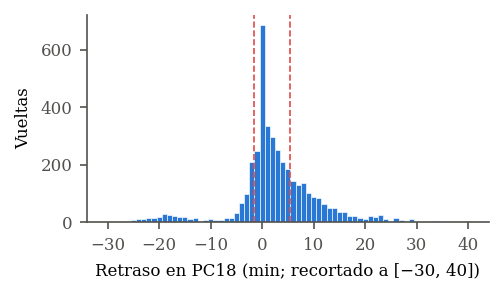

y: media 2.72 | mediana 2 | desv. est. 8.22 min


In [14]:
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "savefig.dpi": 300, "savefig.bbox": "tight"})
AZUL, ROJO, GRIS, VERDE = "#2a78d6", "#e34948", "#c3c2b7", "#2f9e6e"

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, nombre))
    plt.show()

ok = vueltas.y.notna().values          # vueltas con objetivo válido (4 004)
vy = vueltas[ok]

# 1. Distribución del retraso final
fig, ax = plt.subplots(figsize=(3.4, 2.0), dpi=150)
ax.hist(vy.y.clip(-30, 40), bins=np.arange(-30.5, 41.5, 1), color=AZUL, edgecolor="white", linewidth=0.3)
for u, lab in ((UMBRAL_ADELANTO, "−1"), (UMBRAL_RETRASO, "+5")):
    ax.axvline(u + 0.5 if u > 0 else u - 0.5, color=ROJO, lw=0.8, ls="--")
ax.set_xlabel("Retraso en PC18 (min; recortado a [−30, 40])"); ax.set_ylabel("Vueltas")
guardar(fig, "eda1_hist_y.png")
print(f"y: media {vy.y.mean():.2f} | mediana {vy.y.median():.0f} | desv. est. {vy.y.std(ddof=0):.2f} min")


,vueltas,salida_mediana,media_min,pct_retraso,pct_adelanto
dur_prog,,,,,
147.0,642,5:50,-5.09,12.31,52.80
161.0,2700,11:02,3.91,25.96,10.26
168.0,178,17:45,3.89,39.33,13.48
170.0,484,17:37,6.00,53.72,8.06


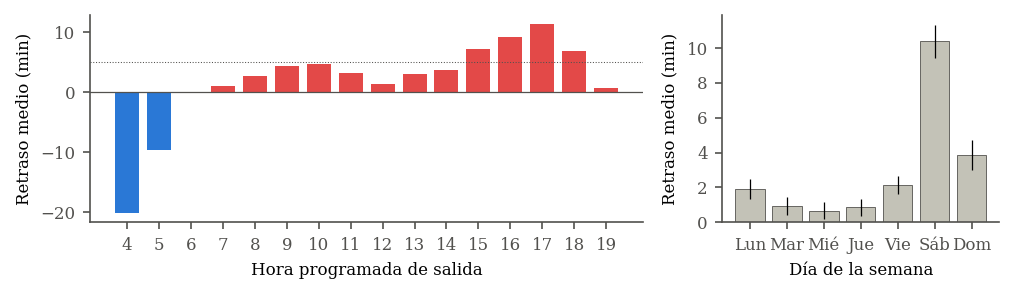

             mean   sem
dia_semana             
0            1.89  0.30
1            0.94  0.27
2            0.66  0.26
3            0.84  0.26
4            2.12  0.26
5           10.40  0.48
6            3.85  0.44


In [15]:
# 2. Retraso según el horario programado (Tabla V)
def hhmm(x):
    return f"{int(x)}:{int(round((x % 1) * 60)):02d}"

tabla_v = (vy.groupby("dur_prog")
             .agg(vueltas=("y", "size"), salida_mediana=("hora_salida", lambda v: hhmm(np.median(v))),
                  media_min=("y", "mean"), pct_retraso=("y", lambda v: (v > UMBRAL_RETRASO).mean() * 100),
                  pct_adelanto=("y", lambda v: (v < UMBRAL_ADELANTO).mean() * 100))
             .round(2))
display(tabla_v)

# 3 y 4. Retraso medio por hora de salida y por día de la semana
fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.0), dpi=150, gridspec_kw={"width_ratios": [2, 1]})
g = vy.groupby(np.floor(vy.hora_salida).astype(int)).y.agg(["mean", "size"])
g = g[g["size"] >= 30]
axs[0].bar(g.index, g["mean"], color=[AZUL if v < 0 else ROJO for v in g["mean"]], width=0.75)
axs[0].axhline(0, color="#52514e", lw=0.6); axs[0].axhline(UMBRAL_RETRASO, color="#52514e", lw=0.5, ls=":")
axs[0].set_xlabel("Hora programada de salida"); axs[0].set_ylabel("Retraso medio (min)"); axs[0].set_xticks(g.index)
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
gd = vy.groupby("dia_semana").y.agg(["mean", "sem"])
axs[1].bar([DIAS[d] for d in gd.index], gd["mean"], yerr=1.96 * gd["sem"], color=GRIS, edgecolor="#52514e",
           linewidth=0.4, error_kw={"lw": 0.6})
axs[1].set_ylabel("Retraso medio (min)"); axs[1].set_xlabel("Día de la semana")
guardar(fig, "eda2_hora_dia.png")
print(gd.round(2).to_string())


tramo  media_min  desv_min
  1-2      -0.67      0.57
  2-3       0.25      1.40
  3-4       0.88      1.43
  4-5      -0.22      1.75
  5-6       1.17      2.72
  6-7      -0.60      0.49
  7-8       0.87      1.27
  8-9      -0.46      1.50
 9-10      -0.54      1.60
10-11       0.21      1.38
11-12       0.39      2.26
12-13       0.50      2.17
13-14       2.79      2.24
14-15      -1.96      0.81
15-16       0.92      3.34
16-17       1.03      0.94
17-18      -0.92      1.57


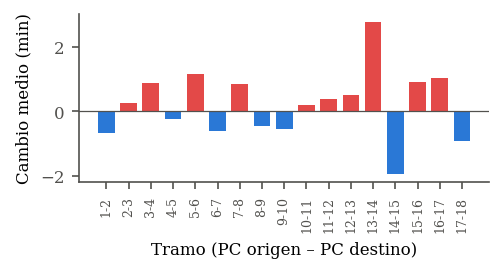

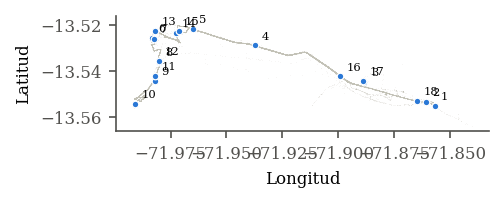

In [16]:
# 5. Cambio medio del retraso por tramo (Fig. 3)
inc = np.diff(D[ok], axis=1)
tramos = pd.DataFrame({"tramo": [f"{j}-{j+1}" for j in range(1, 18)],
                       "media_min": np.nanmean(inc, 0), "desv_min": np.nanstd(inc, 0)}).round(2)
print(tramos.to_string(index=False))

fig, ax = plt.subplots(figsize=(3.4, 1.9), dpi=150)
x = np.arange(1, 18)
ax.bar(x, tramos.media_min, color=[AZUL if v < 0 else ROJO for v in tramos.media_min], width=0.75)
ax.axhline(0, color="#52514e", lw=0.6)
ax.set_xticks(x); ax.set_xticklabels(tramos.tramo, rotation=90, fontsize=6)
ax.set_xlabel("Tramo (PC origen – PC destino)"); ax.set_ylabel("Cambio medio (min)")
guardar(fig, "eda3_tramos.png")

# 6. Mapa de la ruta con los PC
fondo = mon[["latitude", "longitude"]].sample(60000, random_state=0)
fondo = fondo[fondo.longitude.between(-72.01, -71.84) & fondo.latitude.between(-13.57, -13.51)]
fig, ax = plt.subplots(figsize=(3.4, 2.3), dpi=150)
ax.scatter(fondo.longitude, fondo.latitude, s=0.05, c=GRIS, alpha=0.4, linewidths=0, rasterized=True)
for j, (la, lo) in enumerate(PCS, 1):
    ax.scatter(lo, la, s=10, c=AZUL, edgecolors="white", linewidths=0.6, zorder=3)
    ax.annotate(str(j), (lo, la), xytext=(3, 3), textcoords="offset points", fontsize=5.5)
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.set_aspect(1 / np.cos(np.radians(13.54)))
guardar(fig, "eda4_mapa.png")


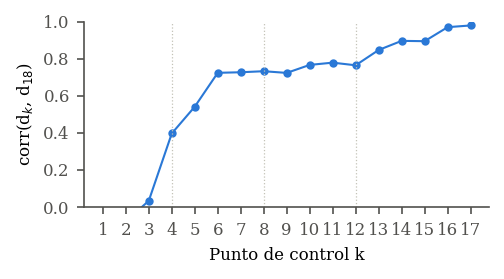

PC1    -0.070
PC2    -0.077
PC3     0.034
PC4     0.397
PC5     0.541
PC6     0.723
PC7     0.726
PC8     0.732
PC9     0.723
PC10    0.766
PC11    0.778
PC12    0.764
PC13    0.847
PC14    0.896
PC15    0.894
PC16    0.969
PC17    0.979


In [17]:
# 7. Correlación entre el retraso en PC k y el retraso final (motiva K_VALUES)
corr = [pd.Series(D[ok, j]).corr(pd.Series(D[ok, 17])) for j in range(17)]
fig, ax = plt.subplots(figsize=(3.4, 1.9), dpi=150)
ax.plot(range(1, 18), corr, marker="o", ms=3, color=AZUL, lw=1)
for kk in K_VALUES[1:]:
    ax.axvline(kk, color=GRIS, lw=0.6, ls=":")
ax.set_xticks(range(1, 18)); ax.set_ylim(0, 1)
ax.set_xlabel("Punto de control k"); ax.set_ylabel("corr(d$_k$, d$_{18}$)")
guardar(fig, "eda5_corr_k.png")
print(pd.Series(np.round(corr, 3), index=[f"PC{j}" for j in range(1, 18)]).to_string())


## 5. Ingeniería de variables (OE4)

Tres conjuntos de variables (Sección IV-G del paper):

| Conjunto | Contenido | Escenario |
|---|---|---|
| **F0** | hora programada de salida, día de la semana, número de vuelta, duración programada y vehículo | k = 0 y base de todos |
| **F1** | F0 + desviaciones `D[:, 0:k]` | k = 4, 8, 12 |
| **F2** | F1 + agregados GPS de los tramos ya recorridos: velocidad media ponderada por tiempo, desviación de la velocidad y minutos detenido | k = 4, 8, 12 (ablación H3) |

**Regla anti-fuga (crítica):** toda variable para el escenario *k* debe usar **solo información disponible al pasar por PC k**. Para el GPS, eso significa usar solo registros con `t ≤ E[i, k-1]`. Si se usa información posterior, el modelo "ve el futuro" y los resultados no son válidos.

**Faltantes en `D[:, 0:k]`:**
- XGBoost acepta `NaN` de forma nativa.
- Ridge, Logística y Random Forest requieren imputación: último valor observado (*forward fill* a lo largo de los PC) más una columna indicadora de faltante.

**Codificación:**
- Modelos lineales: one-hot para día, vuelta, horario y vehículo; estandarizar las numéricas.
- Modelos de árboles: no necesitan escalado.

In [18]:
VEL_DETENIDO = 3     # km/h: por debajo se considera detenido
DT_MAX = 300         # s: un intervalo mayor entre registros se trata como corte del GPS y se recorta a 300 s

def _agregados(ss, sp, t0, t1):
    """Velocidad media ponderada por tiempo, su desviación y minutos detenido entre t0 y t1.
    Cada registro pesa el tiempo hasta el siguiente (el GPS reporta menos cuando el bus está detenido)."""
    if np.isnan(t0) or np.isnan(t1) or t1 <= t0:
        return [np.nan] * 3
    a, b = np.searchsorted(ss, t0), np.searchsorted(ss, t1, side="right")
    if b - a < 3:
        return [np.nan] * 3
    s2, v2 = ss[a:b], sp[a:b]
    dt = np.clip(np.diff(s2, append=t1), 0, DT_MAX)
    if dt.sum() <= 0:
        return [np.nan] * 3
    vmed = np.average(v2, weights=dt)
    vdesv = np.sqrt(np.average((v2 - vmed) ** 2, weights=dt))
    return [vmed, vdesv, dt[v2 <= VEL_DETENIDO].sum() / 60]

def agregados_gps(k):
    """Variables GPS del escenario k para todas las vueltas. Anti-fuga: solo registros con t <= paso real por PC k.
    Si la hora real de PC k es inválida, se usa el último PC válido anterior (información que sí existía)."""
    filas = []
    for i in range(len(vueltas)):
        key = (vueltas.vehicle_id_id.iat[i], vueltas.date.iat[i])
        val = np.flatnonzero(~np.isnan(E_ok[i, :k]))
        if key not in GPS or len(val) == 0:
            filas.append([np.nan] * 6); continue
        ss, sp = GPS[key][0], GPS[key][1]
        t_ini = E_ok[i, 0] if not np.isnan(E_ok[i, 0]) else S[i, 0]
        t_fin = E_ok[i, val[-1]]
        t_ult = E_ok[i, val[-2]] if len(val) >= 2 else t_ini
        filas.append(_agregados(ss, sp, t_ini, t_fin) + _agregados(ss, sp, t_ult, t_fin))
    cols = ["gps_vel_media", "gps_vel_desv", "gps_min_detenido",
            "gps_vel_media_ult", "gps_vel_desv_ult", "gps_min_detenido_ult"]
    return pd.DataFrame(filas, columns=cols)

t0 = time.time()
GPS_K = {k: agregados_gps(k) for k in K_VALUES if k > 0}
print(f"Agregados GPS calculados en {time.time() - t0:.0f} s")
for k, g in GPS_K.items():
    print(f"k={k:2d}: vueltas sin agregados GPS {g.gps_vel_media.isna().sum()} | "
          f"corr(min detenido, y) = {g.gps_min_detenido[ok].corr(vueltas.y[ok]):.3f}")
GPS_K[12].describe().round(2)


Agregados GPS calculados en 4 s
k= 4: vueltas sin agregados GPS 87 | corr(min detenido, y) = 0.108
k= 8: vueltas sin agregados GPS 87 | corr(min detenido, y) = 0.262
k=12: vueltas sin agregados GPS 87 | corr(min detenido, y) = 0.274


,gps_vel_media,gps_vel_desv,gps_min_detenido,gps_vel_media_ult,gps_vel_desv_ult,gps_min_detenido_ult
count,4472.00,4472.00,4472.00,4444.00,4444.00,4444.00
mean,22.69,11.19,2.27,18.58,7.53,0.25
std,2.13,1.27,2.29,5.18,2.78,0.87
min,9.23,1.66,0.00,2.99,0.74,0.00
25%,21.42,10.46,0.62,15.27,5.61,0.00
50%,22.53,11.15,1.75,18.60,7.41,0.00
75%,23.75,11.88,3.28,21.85,9.27,0.00
max,42.64,20.59,27.42,42.64,19.78,10.00


In [19]:
CAT_COLS = ["dia_semana", "lap", "dur_prog", "vehiculo"]

def construir_features(vueltas, D, k, conjunto="F1", gps=None, para_lineal=False, imputar=None):
    """Matriz X del escenario k (una fila por vuelta, mismas filas que `vueltas`).
       conjunto   : "F0", "F1" o "F2"
       gps        : DataFrame de agregados GPS del escenario k (solo F2)
       para_lineal: True -> categóricas como texto (one-hot en el Pipeline) y hora²
       imputar    : True -> faltantes de d1..dk con el último valor observado (0 si no hay) + indicador.
                    Por defecto True si para_lineal. Para Random Forest se pasa imputar=True; XGBoost usa NaN."""
    if imputar is None:
        imputar = para_lineal
    X = pd.DataFrame({
        "hora_salida": vueltas["hora_salida"].values,
        "dia_semana": vueltas["dia_semana"].values,
        "lap": vueltas["lap"].values,
        "dur_prog": vueltas["dur_prog"].values,
        "vehiculo": vueltas["vehicle_id_id"].astype(int).values,
    })
    if para_lineal:
        X["hora_salida2"] = X["hora_salida"] ** 2     # el efecto de la hora no es lineal (Fig. 2)
        for c in CAT_COLS:
            X[c] = X[c].astype(str)
    if conjunto in ("F1", "F2") and k > 0:
        Dk = pd.DataFrame(D[:, :k], columns=[f"d{j}" for j in range(1, k + 1)])
        if imputar:
            ind = Dk.isna().astype(int).add_suffix("_falta")
            Dk = Dk.ffill(axis=1).fillna(0)        # imputación dentro de la fila: no usa otras vueltas (sin fuga)
            Dk = pd.concat([Dk, ind], axis=1)
        X = pd.concat([X, Dk], axis=1)
    if conjunto == "F2" and k > 0:
        X = pd.concat([X, gps.reset_index(drop=True)], axis=1)
    return X

# Ejemplo: las columnas que ve cada modelo en k = 4 con F2
for modo, kw in (("XGBoost", {}), ("Random Forest", {"imputar": True}), ("Lineal", {"para_lineal": True})):
    print(f"{modo:14s}", list(construir_features(vueltas, D, 4, "F2", GPS_K[4], **kw).columns))


XGBoost        ['hora_salida', 'dia_semana', 'lap', 'dur_prog', 'vehiculo', 'd1', 'd2', 'd3', 'd4', 'gps_vel_media', 'gps_vel_desv', 'gps_min_detenido', 'gps_vel_media_ult', 'gps_vel_desv_ult', 'gps_min_detenido_ult']
Random Forest  ['hora_salida', 'dia_semana', 'lap', 'dur_prog', 'vehiculo', 'd1', 'd2', 'd3', 'd4', 'd1_falta', 'd2_falta', 'd3_falta', 'd4_falta', 'gps_vel_media', 'gps_vel_desv', 'gps_min_detenido', 'gps_vel_media_ult', 'gps_vel_desv_ult', 'gps_min_detenido_ult']
Lineal         ['hora_salida', 'dia_semana', 'lap', 'dur_prog', 'vehiculo', 'hora_salida2', 'd1', 'd2', 'd3', 'd4', 'd1_falta', 'd2_falta', 'd3_falta', 'd4_falta', 'gps_vel_media', 'gps_vel_desv', 'gps_min_detenido', 'gps_vel_media_ult', 'gps_vel_desv_ult', 'gps_min_detenido_ult']


## 6. Partición temporal

- **Prueba:** desde `TEST_INICIO` (5 días, 758 vueltas con `y` válido). **No se toca hasta la etapa 9.**
- **Desarrollo:** 22 días (3 246 vueltas). Sobre él se aplican los 4 pliegues de `CV_FOLDS`.

**Por qué temporal y no aleatoria:** las vueltas de un mismo día comparten condiciones (tráfico, eventos). Una partición aleatoria pondría vueltas "hermanas" en entrenamiento y validación, y sobreestimaría el desempeño. Además, en la operación real siempre se predice el futuro con datos del pasado.

In [20]:
fechas = vueltas["date"].values            # 'YYYY-MM-DD': se pueden comparar como texto
mascara_test = fechas >= TEST_INICIO
mascara_dev  = (fechas >= DEV_INICIO) & (fechas < TEST_INICIO)

# Conjunto de modelado: solo vueltas con objetivo válido
vm = vueltas[ok].reset_index(drop=True)
Dm = D[ok]
es_test, es_dev = mascara_test[ok], mascara_dev[ok]
y_reg = vm["y"].values
y_clf = vm["clase"].values.astype(int)

def indices_fold(vueltas, fin_tr, ini_va, fin_va):
    # Devuelve (idx_train, idx_val) para un pliegue de CV_FOLDS (posiciones dentro de `vueltas`)
    f = vueltas["date"].values
    idx_tr = np.flatnonzero((f >= DEV_INICIO) & (f <= fin_tr))
    idx_va = np.flatnonzero((f >= ini_va) & (f <= fin_va))
    return idx_tr, idx_va

FOLDS = [indices_fold(vm, *f) for f in CV_FOLDS]
IDX_DEV, IDX_TEST = np.flatnonzero(es_dev), np.flatnonzero(es_test)
for n, (a, b) in enumerate(FOLDS, 1):
    print(f"Pliegue {n}: entrenamiento {len(a)} vueltas | validación {len(b)} vueltas")
print(f"Desarrollo: {len(IDX_DEV)} | Prueba: {len(IDX_TEST)}")


Pliegue 1: entrenamiento 1503 vueltas | validación 451 vueltas
Pliegue 2: entrenamiento 1954 vueltas | validación 377 vueltas
Pliegue 3: entrenamiento 2331 vueltas | validación 505 vueltas
Pliegue 4: entrenamiento 2836 vueltas | validación 410 vueltas
Desarrollo: 3246 | Prueba: 758


#### ✅ Verificación 6

In [21]:
def verificar_6(vueltas, mascara_test, mascara_dev):
    v = vueltas["y"].notna()
    assert int((v & mascara_test).sum()) == 758
    assert int((v & mascara_dev).sum()) == 3246
    print("6 correcto ✔")

verificar_6(vueltas, mascara_test, mascara_dev)


6 correcto ✔


## 7. Líneas base (H1)

| Línea base | Regresión | Clasificación |
|---|---|---|
| **B1. Persistencia** (solo k > 0) | `ŷ = último retraso observado en PC1..PCk` | clase de ese valor |
| **B2. Histórica** | promedio de `y` en entrenamiento por hora de salida | clase mayoritaria |

**Por qué:** un modelo de ML solo aporta valor si supera estas reglas simples (Taparia [9]; Liu *et al.* [6]).

Referencia preliminar (entrenamiento 06–23/01, validación 24–27/01):
- B2 da MAE ≈ 5,36 min; la media global, ≈ 6,69 min; la clase mayoritaria, F1-macro ≈ 0,22.
- Persistencia: k=4 → 7,05; k=8 → 5,04; k=12 → 4,41.

In [22]:
# ---------- Métricas ----------
def metricas_reg(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "R2": r2_score(y, p)}

def metricas_clf(y, p, proba=None):
    m = {"F1_macro": f1_score(y, p, average="macro"),
         "recall_retrasado": recall_score(y, p, labels=[2], average="macro", zero_division=0)}
    if proba is not None:
        m["PR_AUC"] = average_precision_score(label_binarize(y, classes=[0, 1, 2]), proba, average="macro")
    return m

# ---------- Líneas base ----------
def pred_persistencia(D_, k):
    """B1: el retraso final es el último retraso observado en PC1..PCk (0 si no hay ninguno)."""
    return pd.DataFrame(D_[:, :k]).ffill(axis=1).iloc[:, -1].fillna(0).values

def pred_historico(v_tr, y_tr, v_ap):
    """B2: promedio de y en entrenamiento por hora de salida (media global si la hora no aparece)."""
    h_tr, h_ap = np.floor(v_tr["hora_salida"].values), np.floor(v_ap["hora_salida"].values)
    medias = pd.Series(y_tr).groupby(h_tr).mean()
    return pd.Series(h_ap).map(medias).fillna(y_tr.mean()).values

def lineas_base(idx_tr, idx_ap, k):
    """Predicciones de las líneas base (regresión y clasificación) para las vueltas idx_ap."""
    out = {}
    v_tr, v_ap = vm.iloc[idx_tr], vm.iloc[idx_ap]
    p = pred_historico(v_tr, y_reg[idx_tr], v_ap)
    may = np.bincount(y_clf[idx_tr]).argmax()
    out["B2 histórico"] = {"reg": p, "clf": np.full(len(idx_ap), may),
                           "proba": np.eye(3)[np.full(len(idx_ap), may)]}
    if k > 0:
        p = pred_persistencia(Dm[idx_ap], k)
        c = a_clase(p).astype(int)
        out["B1 persistencia"] = {"reg": p, "clf": c, "proba": np.eye(3)[c]}
    return out

# Comprobación con el análisis preliminar (entrenamiento 06–23/01, validación 24–27/01)
f = vm["date"].values
tr_p, va_p = np.flatnonzero(es_dev & (f <= "2025-01-23")), np.flatnonzero(es_dev & (f >= "2025-01-24"))
print(f"B2 histórico   : MAE {mean_absolute_error(y_reg[va_p], lineas_base(tr_p, va_p, 0)['B2 histórico']['reg']):.2f} (ref. 5,36)")
print(f"Clase mayoritaria: F1-macro {f1_score(y_clf[va_p], lineas_base(tr_p, va_p, 0)['B2 histórico']['clf'], average='macro'):.2f} (ref. 0,22)")
for k in (4, 8, 12):
    print(f"Persistencia k={k:2d}: MAE {mean_absolute_error(y_reg[va_p], pred_persistencia(Dm[va_p], k)):.2f}", "(ref. 7,05 / 5,04 / 4,41)")

# Líneas base en los 4 pliegues
filas = []
for k in K_VALUES:
    for n, (a, b) in enumerate(FOLDS, 1):
        for nombre, pr in lineas_base(a, b, k).items():
            filas.append({"modelo": nombre, "k": k, "pliegue": n, **metricas_reg(y_reg[b], pr["reg"]),
                          **metricas_clf(y_clf[b], pr["clf"])})
cv_base = (pd.DataFrame(filas).groupby(["modelo", "k"])
             .agg(MAE_media=("MAE", "mean"), MAE_std=("MAE", "std"),
                  F1_macro_media=("F1_macro", "mean"), F1_macro_std=("F1_macro", "std"),
                  recall_retrasado=("recall_retrasado", "mean")).round(3))
cv_base.to_csv(os.path.join(OUT_DIR, "resultados_cv_lineas_base.csv"))
cv_base


B2 histórico   : MAE 5.36 (ref. 5,36)
Clase mayoritaria: F1-macro 0.22 (ref. 0,22)
Persistencia k= 4: MAE 7.05 (ref. 7,05 / 5,04 / 4,41)
Persistencia k= 8: MAE 5.04 (ref. 7,05 / 5,04 / 4,41)
Persistencia k=12: MAE 4.41 (ref. 7,05 / 5,04 / 4,41)


MAE_media  MAE_std  F1_macro_media  F1_macro_std  recall_retrasado
modelo          k                                                                     
B1 persistencia 4       5.983    1.757           0.403         0.033             0.034
                8       4.574    0.949           0.557         0.082             0.245
                12      4.374    0.439           0.562         0.120             0.295
B2 histórico    0       4.444    1.515           0.231         0.022             0.000
                4       4.444    1.515           0.231         0.022             0.000
                8       4.444    1.515           0.231         0.022             0.000
                12      4.444    1.515           0.231         0.022             0.000

## 8. Modelos y ajuste de hiperparámetros (OE3)

| Modelo | Regresión | Clasificación | Antecedentes |
|---|---|---|---|
| M1 | `Ridge` | `LogisticRegression` (multinomial) | [9], [11] |
| M2 | `RandomForestRegressor` | `RandomForestClassifier` | [7], [10] |
| M3 | `XGBRegressor` | `XGBClassifier` | [7], [8], [9] |

**Procedimiento por modelo, tarea y escenario (k, conjunto):**
1. Para cada combinación de la malla completa (`GRIDS_REG` / `GRIDS_CLF`), entrenar y evaluar en los 4 pliegues temporales.
2. Elegir la combinación con **menor MAE medio** (regresión) o **mayor F1-macro medio** (clasificación).
3. Guardar media ± desviación estándar entre pliegues, como las reporta el paper.

**Implementación.** El bucle es propio (no `GridSearchCV`) para guardar cada combinación apenas termina y poder retomar tras una desconexión. Para `n_estimators`, cada Random Forest y XGBoost se entrena una vez con el valor máximo y se evalúan sus primeros 200/400/800 árboles: el resultado es idéntico a entrenar cada tamaño por separado (se comprueba abajo) y reduce el tiempo a unos 28 min. En total: 1 239 combinaciones × 4 pliegues.


In [23]:
# ---------- Matrices de variables de las 7 combinaciones (se construyen una sola vez) ----------
MODO_X = {"xgb": {}, "rf": {"imputar": True}, "ridge": {"para_lineal": True}, "logistic": {"para_lineal": True}}
XS = {}
for k, conj in ESCENARIOS:
    gps = GPS_K[k].iloc[np.flatnonzero(ok)] if conj == "F2" else None
    XS[(k, conj)] = {m: construir_features(vm, Dm, k, conj, gps, **kw) for m, kw in MODO_X.items()}
    print(f"k={k:2d} {conj}: {XS[(k, conj)]['xgb'].shape[1]} variables (XGBoost) | "
          f"{XS[(k, conj)]['ridge'].shape[1]} antes del one-hot (lineales)")

# ---------- Modelos ----------
def preprocesador_lineal(X):
    """Solo las numéricas se estandarizan; one-hot e indicadores de faltante quedan en 0/1.
    Se ajusta dentro del Pipeline, es decir, solo con el entrenamiento de cada pliegue."""
    cat = [c for c in CAT_COLS if c in X.columns]
    ind = [c for c in X.columns if c.endswith("_falta")]
    num = [c for c in X.columns if c not in cat and c not in ind]
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
        ("ind", "passthrough", ind)])

def crear_modelo(tarea, modelo, params, X):
    p = dict(params)
    if modelo == "ridge":
        return Pipeline([("pre", preprocesador_lineal(X)), ("m", Ridge(**p))])
    if modelo == "logistic":
        return Pipeline([("pre", preprocesador_lineal(X)), ("m", LogisticRegression(max_iter=3000, **p))])
    if modelo == "rf":
        cls = RandomForestRegressor if tarea == "reg" else RandomForestClassifier
        # el imputador solo actúa sobre los agregados GPS faltantes (F2); d1..dk ya vienen imputados
        return Pipeline([("imp", SimpleImputer(strategy="median")),
                         ("m", cls(random_state=SEED, n_jobs=-1, **p))])
    if modelo == "xgb":
        p.pop("class_weight", None)
        cls = XGBRegressor if tarea == "reg" else XGBClassifier
        return cls(random_state=SEED, n_jobs=-1, tree_method="hist", **p)
    raise ValueError(modelo)

def ajustar(tarea, modelo, params, X, y):
    m = crear_modelo(tarea, modelo, params, X)
    kw = {}
    if modelo == "xgb" and tarea == "clf" and params.get("class_weight") == "balanced":
        kw["sample_weight"] = compute_sample_weight("balanced", y)
    return m.fit(X, y, **kw)

def predecir(tarea, m, X):
    if tarea == "reg":
        return m.predict(X), None
    proba = m.predict_proba(X)
    return proba.argmax(1), proba

def predecir_variantes(tarea, modelo, m, X, n_list):
    """Predicciones para cada n_estimators de la malla usando los primeros n árboles del modelo de mayor tamaño.
    Es exactamente igual a entrenar un modelo con n árboles: en ambos casos los árboles se generan en el mismo
    orden y con la misma semilla (se comprueba en la celda siguiente). Ahorra ~3x de cómputo en XGBoost."""
    if n_list == [None]:
        return {None: predecir(tarea, m, X)}
    res = {}
    for n in n_list:
        if modelo == "xgb":
            if tarea == "reg":
                res[n] = (m.predict(X, iteration_range=(0, n)), None)
            else:
                pr = m.predict_proba(X, iteration_range=(0, n))
                res[n] = (pr.argmax(1), pr)
        else:
            Xt, est = m[:-1].transform(X), m[-1].estimators_[:n]
            if tarea == "reg":
                res[n] = (np.mean([t.predict(Xt) for t in est], axis=0), None)
            else:
                pr = np.mean([t.predict_proba(Xt) for t in est], axis=0)
                res[n] = (pr.argmax(1), pr)
    return res


k= 0 F0: 5 variables (XGBoost) | 6 antes del one-hot (lineales)
k= 4 F1: 9 variables (XGBoost) | 14 antes del one-hot (lineales)
k= 8 F1: 13 variables (XGBoost) | 22 antes del one-hot (lineales)
k=12 F1: 17 variables (XGBoost) | 30 antes del one-hot (lineales)
k= 4 F2: 15 variables (XGBoost) | 20 antes del one-hot (lineales)
k= 8 F2: 19 variables (XGBoost) | 28 antes del one-hot (lineales)
k=12 F2: 23 variables (XGBoost) | 36 antes del one-hot (lineales)


#### Comprobación: sub-conjuntos de árboles

Los primeros *n* árboles del modelo de mayor tamaño deben dar las mismas predicciones que un modelo entrenado con *n* árboles.

In [24]:
# Comprobación: los primeros n árboles del modelo grande == modelo entrenado con n árboles
a, b = FOLDS[0]
X = XS[(8, "F1")]
for tarea, y in (("reg", y_reg), ("clf", y_clf)):
    for modelo, p in (("rf", {"max_depth": 10, "min_samples_leaf": 5}), ("xgb", {"learning_rate": 0.1, "max_depth": 4, "subsample": 0.8})):
        Xm = X[modelo]
        grande = ajustar(tarea, modelo, {**p, "n_estimators": 400}, Xm.iloc[a], y[a])
        chico = ajustar(tarea, modelo, {**p, "n_estimators": 200}, Xm.iloc[a], y[a])
        v = predecir_variantes(tarea, modelo, grande, Xm.iloc[b], [200])[200]
        c = predecir(tarea, chico, Xm.iloc[b])
        dif = np.abs((v[1] if tarea == "clf" else v[0]) - (c[1] if tarea == "clf" else c[0])).max()
        print(f"{tarea} {modelo}: diferencia máxima = {dif:.2e}")
        assert dif < 1e-5
print("Equivalencia comprobada ✔")


reg rf: diferencia máxima = 3.55e-15
reg xgb: diferencia máxima = 0.00e+00
clf rf: diferencia máxima = 2.22e-16
clf xgb: diferencia máxima = 0.00e+00
Equivalencia comprobada ✔


#### Búsqueda en malla

Es la celda más lenta. Guarda cada combinación en `resultados/resultados_cv_raw.csv` apenas termina; si Colab se desconecta, vuelva a ejecutar todo el notebook y continuará desde donde quedó.

In [25]:
# ---------- Búsqueda en malla con validación cruzada temporal ----------
# Guarda una fila por combinación de hiperparámetros apenas termina sus 4 pliegues. Si Colab se desconecta,
# basta con volver a ejecutar el notebook: las combinaciones ya guardadas se saltan.
ARCH_CV = os.path.join(OUT_DIR, "resultados_cv_raw.csv" if not MODO_RAPIDO else "resultados_cv_rapido.csv")
MODELOS = {"reg": ["ridge", "rf", "xgb"], "clf": ["logistic", "rf", "xgb"]}
COLS = ["clave", "tarea", "modelo", "k", "conjunto", "params", "metrica", "metrica_media", "metrica_std",
        "pliegue1", "pliegue2", "pliegue3", "pliegue4", "RMSE_media", "R2_media", "recall_retrasado_media",
        "PR_AUC_media", "segundos"]

def configuraciones(tarea, modelo):
    grid = (GRIDS_REG if tarea == "reg" else GRIDS_CLF)[modelo]
    n_list = grid.get("n_estimators", [None])
    resto = {p: v for p, v in grid.items() if p != "n_estimators"}
    for params in ParameterGrid(resto):
        yield params, n_list

def clave(tarea, modelo, k, conj, params):
    return f"{tarea}|{modelo}|{k}|{conj}|{json.dumps(params, sort_keys=True)}"

hechos = set(pd.read_csv(ARCH_CV).clave) if os.path.exists(ARCH_CV) else set()
trabajos = [(t, m, k, c, p, n) for t in ("reg", "clf") for (k, c) in ESCENARIOS for m in MODELOS[t]
            for p, n in configuraciones(t, m)]
pend = [w for w in trabajos
        if any(clave(w[0], w[1], w[2], w[3], {**w[4], **({} if n is None else {"n_estimators": n})}) not in hechos
               for n in w[5])]
n_comb = sum(len(w[5]) for w in trabajos)
print(f"Combinaciones de hiperparámetros × escenarios: {n_comb} | entrenamientos necesarios: {len(trabajos)} × 4 pliegues")
print(f"Ya guardados: {len(hechos)} | pendientes: {len(pend)} entrenamientos × 4 pliegues")

t_ini = time.time()
for w_i, (tarea, modelo, k, conj, params, n_list) in enumerate(pend, 1):
    t0 = time.time()
    X, y = XS[(k, conj)][modelo], (y_reg if tarea == "reg" else y_clf)
    fit_params = dict(params) if n_list == [None] else {**params, "n_estimators": max(n_list)}
    por_n = {n: [] for n in n_list}
    for a, b in FOLDS:
        m = ajustar(tarea, modelo, fit_params, X.iloc[a], y[a])
        for n, (pred, proba) in predecir_variantes(tarea, modelo, m, X.iloc[b], n_list).items():
            por_n[n].append(metricas_reg(y[b], pred) if tarea == "reg" else metricas_clf(y[b], pred, proba))
    filas = []
    for n, mets in por_n.items():
        p = dict(params) if n is None else {**params, "n_estimators": n}
        met = "MAE" if tarea == "reg" else "F1_macro"
        vals = [mm[met] for mm in mets]
        filas.append({"clave": clave(tarea, modelo, k, conj, p), "tarea": tarea, "modelo": modelo, "k": k,
                      "conjunto": conj, "params": json.dumps(p, sort_keys=True), "metrica": met,
                      "metrica_media": np.mean(vals), "metrica_std": np.std(vals, ddof=1),
                      **{f"pliegue{j}": v for j, v in enumerate(vals, 1)},
                      "RMSE_media": np.mean([mm.get("RMSE", np.nan) for mm in mets]),
                      "R2_media": np.mean([mm.get("R2", np.nan) for mm in mets]),
                      "recall_retrasado_media": np.mean([mm.get("recall_retrasado", np.nan) for mm in mets]),
                      "PR_AUC_media": np.mean([mm.get("PR_AUC", np.nan) for mm in mets]),
                      "segundos": (time.time() - t0) / len(n_list)})
    pd.DataFrame(filas, columns=COLS).to_csv(ARCH_CV, mode="a", header=not os.path.exists(ARCH_CV), index=False)
    if w_i % 10 == 0 or w_i == len(pend):
        trans = time.time() - t_ini
        print(f"[{w_i}/{len(pend)}] {tarea} {modelo} k={k} {conj} | {trans/60:.1f} min | "
              f"faltan ~{trans / w_i * (len(pend) - w_i) / 60:.0f} min", flush=True)
print("Búsqueda terminada ✔")


Combinaciones de hiperparámetros × escenarios: 1239 | entrenamientos necesarios: 546 × 4 pliegues
Ya guardados: 1239 | pendientes: 0 entrenamientos × 4 pliegues
Búsqueda terminada ✔


#### Mejores configuraciones (media ± desviación estándar entre pliegues)

In [26]:
# ---------- Mejores hiperparámetros por modelo, tarea y escenario (media ± desv. est. entre pliegues) ----------
cv = pd.read_csv(ARCH_CV)
assert len(cv) == n_comb, f"Faltan combinaciones: {len(cv)} de {n_comb}. Vuelva a ejecutar la celda anterior."
cv["orden"] = np.where(cv.tarea == "reg", cv.metrica_media, -cv.metrica_media)
mejores = (cv.sort_values(["orden", "clave"]).drop_duplicates(["tarea", "modelo", "k", "conjunto"])
             .drop(columns="orden").sort_values(["tarea", "modelo", "conjunto", "k"]).reset_index(drop=True))
mejores.to_csv(os.path.join(OUT_DIR, "resultados_cv_mejores.csv"), index=False)
resultados_cv = mejores.to_dict("records")

def tabla_cv(tarea):
    t = mejores[mejores.tarea == tarea].copy()
    t["escenario"] = "k=" + t.k.astype(str) + " " + t.conjunto
    t["valor"] = t.metrica_media.map("{:.3f}".format) + " ± " + t.metrica_std.map("{:.3f}".format)
    orden = [f"k={k} {c}" for k, c in ESCENARIOS]
    tab = t.pivot(index="modelo", columns="escenario", values="valor")[orden]
    base = cv_base.reset_index()
    col = "MAE" if tarea == "reg" else "F1_macro"
    for nombre in ("B1 persistencia", "B2 histórico"):
        fila = {}
        for k, c in ESCENARIOS:
            r = base[(base.modelo == nombre) & (base.k == k)]
            if len(r):
                fila[f"k={k} {c}"] = f"{r[col + '_media'].iat[0]:.3f} ± {r[col + '_std'].iat[0]:.3f}"
        tab.loc[nombre] = pd.Series(fila)
    return tab

print("REGRESIÓN — MAE en validación cruzada (min)")
display(tabla_cv("reg"))
print("CLASIFICACIÓN — F1-macro en validación cruzada")
display(tabla_cv("clf"))
tabla_cv("reg").to_csv(os.path.join(OUT_DIR, "tabla_cv_reg.csv"))
tabla_cv("clf").to_csv(os.path.join(OUT_DIR, "tabla_cv_clf.csv"))
mejores[["tarea", "modelo", "k", "conjunto", "params"]]


REGRESIÓN — MAE en validación cruzada (min)


escenario,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
rf,3.271 ± 0.856,3.255 ± 0.839,3.176 ± 0.739,3.010 ± 0.542,3.239 ± 0.813,3.193 ± 0.768,3.024 ± 0.543
ridge,4.104 ± 0.735,3.946 ± 0.705,3.613 ± 0.628,3.081 ± 0.296,3.954 ± 0.715,3.618 ± 0.631,3.072 ± 0.293
xgb,3.141 ± 0.881,3.179 ± 0.847,3.121 ± 0.788,2.885 ± 0.459,3.179 ± 0.825,3.091 ± 0.778,2.879 ± 0.456
B1 persistencia,NaN,5.983 ± 1.757,4.574 ± 0.949,4.374 ± 0.439,5.983 ± 1.757,4.574 ± 0.949,4.374 ± 0.439
B2 histórico,4.444 ± 1.515,4.444 ± 1.515,4.444 ± 1.515,4.444 ± 1.515,4.444 ± 1.515,4.444 ± 1.515,4.444 ± 1.515


CLASIFICACIÓN — F1-macro en validación cruzada


escenario,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
logistic,0.654 ± 0.075,0.674 ± 0.051,0.695 ± 0.054,0.713 ± 0.070,0.671 ± 0.053,0.694 ± 0.055,0.715 ± 0.066
rf,0.709 ± 0.044,0.711 ± 0.042,0.714 ± 0.050,0.721 ± 0.060,0.703 ± 0.057,0.703 ± 0.054,0.715 ± 0.050
xgb,0.712 ± 0.041,0.706 ± 0.037,0.723 ± 0.055,0.729 ± 0.060,0.706 ± 0.056,0.719 ± 0.056,0.730 ± 0.053
B1 persistencia,NaN,0.403 ± 0.033,0.557 ± 0.082,0.562 ± 0.120,0.403 ± 0.033,0.557 ± 0.082,0.562 ± 0.120
B2 histórico,0.231 ± 0.022,0.231 ± 0.022,0.231 ± 0.022,0.231 ± 0.022,0.231 ± 0.022,0.231 ± 0.022,0.231 ± 0.022


,tarea,modelo,k,conjunto,params
0,clf,logistic,0,F0,"{""C"": 0.1, ""class_weight"": null}"
1,clf,logistic,4,F1,"{""C"": 1, ""class_weight"": null}"
2,clf,logistic,8,F1,"{""C"": 1, ""class_weight"": null}"
3,clf,logistic,12,F1,"{""C"": 1, ""class_weight"": null}"
4,clf,logistic,4,F2,"{""C"": 1, ""class_weight"": null}"
5,clf,logistic,8,F2,"{""C"": 1, ""class_weight"": null}"
6,clf,logistic,12,F2,"{""C"": 1, ""class_weight"": null}"
7,clf,rf,0,F0,"{""class_weight"": null, ""max_depth"": 10, ""min_s..."
8,clf,rf,4,F1,"{""class_weight"": ""balanced"", ""max_depth"": 10, ..."
9,clf,rf,8,F1,"{""class_weight"": null, ""max_depth"": 20, ""min_s..."


## 9. Evaluación final en el conjunto de prueba (OE3, H1)

Entrenar cada modelo con sus **mejores hiperparámetros sobre todo el conjunto de desarrollo** y evaluarlo **una sola vez** en prueba.

**Métricas:**
- Regresión: MAE (principal), RMSE y R².
- Clasificación: F1-macro (principal), *recall* de "retrasado", matriz de confusión y PR-AUC uno contra el resto (`average_precision_score` con `predict_proba`).

**Pruebas estadísticas (α = 0,05):**
- Regresión: Wilcoxon de rangos con signo sobre los **errores absolutos pareados por vuelta** del mejor modelo frente a cada línea base: `wilcoxon(err_modelo, err_base)`.
- Clasificación: McNemar sobre los aciertos pareados. Usen la tabla 2×2 de (acierta modelo, acierta base) y `statsmodels.stats.contingency_tables.mcnemar`.

**Por qué pruebas pareadas:** ambos modelos predicen las **mismas** vueltas, así que se compara la diferencia vuelta a vuelta, no solo los promedios.

In [27]:
# ---------- Entrenamiento final (todo el desarrollo) y evaluación ÚNICA en prueba ----------
y_de = {"reg": y_reg, "clf": y_clf}
PRED = {}            # (tarea, modelo, k, conjunto) -> (pred, proba) en prueba
FINALES = {}         # modelos entrenados (para la importancia de variables)
filas = []
for r in mejores.itertuples():
    X, y = XS[(r.k, r.conjunto)][r.modelo], y_de[r.tarea]
    m = ajustar(r.tarea, r.modelo, json.loads(r.params), X.iloc[IDX_DEV], y[IDX_DEV])
    pred, proba = predecir(r.tarea, m, X.iloc[IDX_TEST])
    FINALES[(r.tarea, r.modelo, r.k, r.conjunto)] = m
    PRED[(r.tarea, r.modelo, r.k, r.conjunto)] = (pred, proba)

# Líneas base (no dependen del conjunto de variables): se registran para F0/F1 y se copian en F2
for k in K_VALUES:
    for nombre, pr in lineas_base(IDX_DEV, IDX_TEST, k).items():
        for conj in (["F0"] if k == 0 else ["F1", "F2"]):
            PRED[("reg", nombre, k, conj)] = (pr["reg"], None)
            PRED[("clf", nombre, k, conj)] = (pr["clf"], pr["proba"])

yt = {"reg": y_reg[IDX_TEST], "clf": y_clf[IDX_TEST]}
for (tarea, modelo, k, conj), (pred, proba) in PRED.items():
    met = metricas_reg(yt[tarea], pred) if tarea == "reg" else metricas_clf(yt[tarea], pred, proba)
    filas.append({"tarea": tarea, "modelo": modelo, "k": k, "conjunto": conj, **met})
resultados_test = pd.DataFrame(filas)

ORDEN_ESC = [f"k={k} {c}" for k, c in ESCENARIOS]
def tabla_test(tarea, met):
    t = resultados_test[resultados_test.tarea == tarea].copy()
    t["escenario"] = "k=" + t.k.astype(str) + " " + t.conjunto
    return t.pivot(index="modelo", columns="escenario", values=met)[ORDEN_ESC].round(3)

for tarea, mets in (("reg", ["MAE", "RMSE", "R2"]), ("clf", ["F1_macro", "recall_retrasado", "PR_AUC"])):
    for met in mets:
        print(f"PRUEBA — {met}")
        display(tabla_test(tarea, met))


PRUEBA — MAE


escenario,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
B1 persistencia,NaN,5.264,3.982,3.670,5.264,3.982,3.670
B2 histórico,4.346,4.346,4.346,4.346,4.346,4.346,4.346
rf,2.650,2.658,2.726,2.494,2.725,2.766,2.546
ridge,3.876,3.770,3.472,2.795,3.773,3.463,2.800
xgb,2.627,2.648,2.655,2.379,2.706,2.685,2.377


PRUEBA — RMSE


escenario,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
B1 persistencia,NaN,8.228,5.967,5.336,8.228,5.967,5.336
B2 histórico,6.227,6.227,6.227,6.227,6.227,6.227,6.227
rf,4.126,4.124,4.198,3.805,4.198,4.225,3.820
ridge,5.330,5.210,4.814,3.956,5.225,4.793,3.947
xgb,4.088,4.079,4.068,3.601,4.127,4.130,3.598


PRUEBA — R2


escenario,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
B1 persistencia,NaN,-0.001,0.473,0.579,-0.001,0.473,0.579
B2 histórico,0.426,0.426,0.426,0.426,0.426,0.426,0.426
rf,0.748,0.748,0.739,0.786,0.739,0.736,0.784
ridge,0.580,0.598,0.657,0.769,0.596,0.660,0.770
xgb,0.753,0.754,0.755,0.808,0.748,0.748,0.809


... (2 outputs left out)

PRUEBA — recall_retrasado


escenario,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
B1 persistencia,NaN,0.000,0.299,0.466,0.000,0.299,0.466
B2 histórico,0.000,0.000,0.000,0.000,0.000,0.000,0.000
logistic,0.494,0.517,0.529,0.557,0.511,0.523,0.552
rf,0.822,0.862,0.759,0.879,0.782,0.776,0.856
xgb,0.718,0.782,0.822,0.805,0.839,0.799,0.805


PRUEBA — PR_AUC


escenario,k=0 F0,k=4 F1,k=8 F1,k=12 F1,k=4 F2,k=8 F2,k=12 F2
modelo,,,,,,,
B1 persistencia,NaN,0.401,0.504,0.548,0.401,0.504,0.548
B2 histórico,0.333,0.333,0.333,0.333,0.333,0.333,0.333
logistic,0.739,0.761,0.773,0.796,0.755,0.772,0.794
rf,0.809,0.805,0.793,0.811,0.779,0.789,0.807
xgb,0.813,0.821,0.808,0.832,0.806,0.802,0.817


#### Pruebas estadísticas y matrices de confusión

,tarea,k,conjunto,mejor_modelo,valor_modelo,base,valor_base,metrica,p_valor,significativo
0,reg,0,F0,xgb,2.627,B2 histórico,4.346,MAE,9.94e-41,True
1,reg,4,F1,xgb,2.648,B1 persistencia,5.264,MAE,6.95e-27,True
2,reg,4,F1,xgb,2.648,B2 histórico,4.346,MAE,3.20e-44,True
3,reg,8,F1,xgb,2.655,B1 persistencia,3.982,MAE,4.39e-20,True
4,reg,8,F1,xgb,2.655,B2 histórico,4.346,MAE,2.60e-39,True
5,reg,12,F1,xgb,2.379,B1 persistencia,3.670,MAE,3.15e-16,True
6,reg,12,F1,xgb,2.379,B2 histórico,4.346,MAE,8.97e-48,True
7,reg,4,F2,xgb,2.706,B1 persistencia,5.264,MAE,1.25e-24,True
8,reg,4,F2,xgb,2.706,B2 histórico,4.346,MAE,5.71e-44,True
9,reg,8,F2,xgb,2.685,B1 persistencia,3.982,MAE,3.37e-18,True



xgb, k=0 F0
              precision    recall  f1-score   support

  adelantado      0.795     0.519     0.628       135
     puntual      0.779     0.886     0.829       449
   retrasado      0.786     0.718     0.751       174

    accuracy                          0.782       758
   macro avg      0.787     0.708     0.736       758
weighted avg      0.783     0.782     0.775       758


xgb, k=12 F1
              precision    recall  f1-score   support

  adelantado      0.839     0.541     0.658       135
     puntual      0.802     0.857     0.829       449
   retrasado      0.733     0.805     0.767       174

    accuracy                          0.789       758
   macro avg      0.791     0.734     0.751       758
weighted avg      0.793     0.789     0.784       758



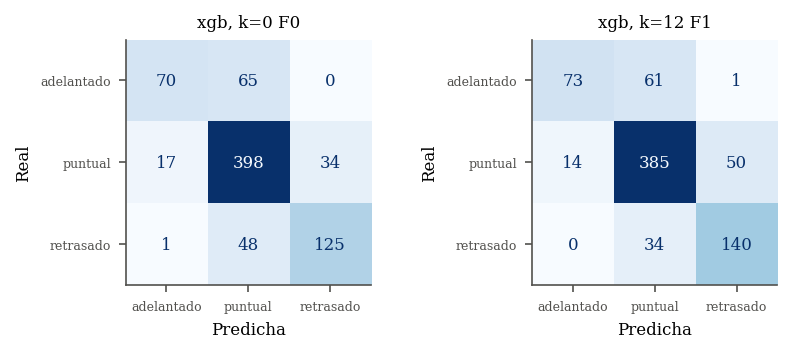

In [28]:
# ---------- Pruebas estadísticas pareadas (α = 0,05) ----------
def p_wilcoxon(err_a, err_b):
    return wilcoxon(err_a, err_b).pvalue if np.any(err_a != err_b) else 1.0

def p_mcnemar(ok_a, ok_b):
    b, c = int((ok_a & ~ok_b).sum()), int((~ok_a & ok_b).sum())
    tabla = [[int((ok_a & ok_b).sum()), b], [c, int((~ok_a & ~ok_b).sum())]]
    exacta = (b + c) < 25
    return mcnemar(tabla, exact=exacta, correction=not exacta).pvalue

def comparar(tarea, clave_a, clave_b):
    """p-valor de la comparación pareada entre dos predicciones sobre las mismas vueltas de prueba."""
    pa, pb = PRED[clave_a][0], PRED[clave_b][0]
    if tarea == "reg":
        return p_wilcoxon(np.abs(yt["reg"] - pa), np.abs(yt["reg"] - pb))
    return p_mcnemar(pa == yt["clf"], pb == yt["clf"])

# El "mejor modelo" de cada escenario se elige con la validación cruzada (no con la prueba)
filas = []
for tarea in ("reg", "clf"):
    met = "MAE" if tarea == "reg" else "F1_macro"
    for k, conj in ESCENARIOS:
        cand = mejores[(mejores.tarea == tarea) & (mejores.k == k) & (mejores.conjunto == conj)]
        best = cand.sort_values("metrica_media", ascending=(tarea == "reg")).modelo.iat[0]
        r_best = resultados_test.set_index(["tarea", "modelo", "k", "conjunto"]).loc[(tarea, best, k, conj)]
        for base in (["B2 histórico"] if k == 0 else ["B1 persistencia", "B2 histórico"]):
            r_base = resultados_test.set_index(["tarea", "modelo", "k", "conjunto"]).loc[(tarea, base, k, conj)]
            p = comparar(tarea, (tarea, best, k, conj), (tarea, base, k, conj))
            filas.append({"tarea": tarea, "k": k, "conjunto": conj, "mejor_modelo": best,
                          f"modelo": round(r_best[met], 3), "base": base, "valor_base": round(r_base[met], 3),
                          "metrica": met, "p_valor": p, "significativo": p < ALPHA_ESTADISTICO})
pruebas_h1 = pd.DataFrame(filas).rename(columns={"modelo": "valor_modelo"})
pruebas_h1["p_valor"] = pruebas_h1.p_valor.map(lambda v: f"{v:.2e}")
display(pruebas_h1)

# Matriz de confusión del mejor clasificador antes de salir (k=0) y en k=12
fig, axs = plt.subplots(1, 2, figsize=(5.6, 2.4), dpi=150)
for ax, (k, conj) in zip(axs, [(0, "F0"), (12, "F1")]):
    best = (mejores[(mejores.tarea == "clf") & (mejores.k == k) & (mejores.conjunto == conj)]
            .sort_values("metrica_media", ascending=False).modelo.iat[0])
    cm = confusion_matrix(yt["clf"], PRED[("clf", best, k, conj)][0], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=list(CLASES.values())).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{best}, k={k} {conj}", fontsize=8); ax.set_xlabel("Predicha"); ax.set_ylabel("Real")
    ax.tick_params(labelsize=6)
    print(f"\n{best}, k={k} {conj}\n" + classification_report(yt["clf"], PRED[("clf", best, k, conj)][0],
                                                              target_names=list(CLASES.values()), digits=3))
guardar(fig, "res_confusion.png")


## 10. Ablaciones (OE4, H2, H3)

1. **Efecto de k (H2):** métrica principal en prueba frente a k = 0, 4, 8, 12 por modelo (F0 en k = 0 y F1 en k > 0), con pruebas pareadas entre escenarios consecutivos y entre k = 0 y k = 12.
2. **Aporte del GPS (H3):** F1 frente a F2 en cada k > 0 y modelo, en validación cruzada y en prueba, con Wilcoxon (regresión) y McNemar (clasificación).


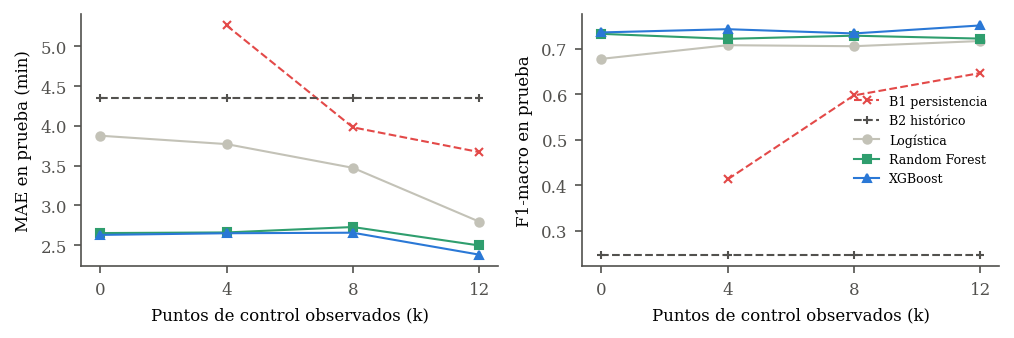

,tarea,modelo,de,a,MAE_de,MAE_a,p_valor,F1_macro_de,F1_macro_a,significativo
0,reg,ridge,k=0,k=4,3.876,3.770,5.103174e-02,NaN,NaN,False
1,reg,ridge,k=4,k=8,3.770,3.472,2.252088e-05,NaN,NaN,True
2,reg,ridge,k=8,k=12,3.472,2.795,5.153700e-21,NaN,NaN,True
3,reg,ridge,k=0,k=12,3.876,2.795,3.326504e-31,NaN,NaN,True
4,reg,rf,k=0,k=4,2.650,2.658,9.326674e-01,NaN,NaN,False
5,reg,rf,k=4,k=8,2.658,2.726,2.347392e-01,NaN,NaN,False
6,reg,rf,k=8,k=12,2.726,2.494,2.074602e-03,NaN,NaN,True
7,reg,rf,k=0,k=12,2.650,2.494,2.721919e-01,NaN,NaN,False
8,reg,xgb,k=0,k=4,2.627,2.648,4.740151e-01,NaN,NaN,False
9,reg,xgb,k=4,k=8,2.648,2.655,6.363145e-01,NaN,NaN,False


,tarea,modelo,k,metrica,CV_F1,CV_F2,prueba_F1,prueba_F2,p_valor,significativo
0,reg,ridge,4,MAE,3.946,3.954,3.770,3.773,0.921468,False
1,reg,ridge,8,MAE,3.613,3.618,3.472,3.463,0.872144,False
2,reg,ridge,12,MAE,3.081,3.072,2.795,2.800,0.269882,False
3,reg,rf,4,MAE,3.255,3.239,2.658,2.725,0.076375,False
4,reg,rf,8,MAE,3.176,3.193,2.726,2.766,0.119107,False
5,reg,rf,12,MAE,3.010,3.024,2.494,2.546,0.108502,False
6,reg,xgb,4,MAE,3.179,3.179,2.648,2.706,0.001085,True
7,reg,xgb,8,MAE,3.121,3.091,2.655,2.685,0.636433,False
8,reg,xgb,12,MAE,2.885,2.879,2.379,2.377,0.129709,False
9,clf,logistic,4,F1_macro,0.674,0.671,0.708,0.696,0.109375,False


In [29]:
# ---------- H2: efecto de k (F0 en k=0; F1 en k>0) ----------
NOMBRES = {"ridge": "Ridge", "logistic": "Logística", "rf": "Random Forest", "xgb": "XGBoost",
           "B1 persistencia": "B1 persistencia", "B2 histórico": "B2 histórico"}
ESTILO = {"ridge": (GRIS, "o"), "logistic": (GRIS, "o"), "rf": (VERDE, "s"), "xgb": (AZUL, "^"),
          "B1 persistencia": (ROJO, "x"), "B2 histórico": ("#52514e", "+")}
fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.3), dpi=150)
for ax, tarea, met, lab in ((axs[0], "reg", "MAE", "MAE en prueba (min)"), (axs[1], "clf", "F1_macro", "F1-macro en prueba")):
    t = resultados_test[(resultados_test.tarea == tarea) & (resultados_test.conjunto != "F2")]
    for modelo, g in t.groupby("modelo"):
        g = g.sort_values("k")
        c, mk = ESTILO[modelo]
        ls = "--" if modelo.startswith("B") else "-"
        ax.plot(g.k, g[met], ls, marker=mk, color=c, ms=4, lw=1, label=NOMBRES[modelo])
    ax.set_xticks(K_VALUES); ax.set_xlabel("Puntos de control observados (k)"); ax.set_ylabel(lab)
axs[1].legend(fontsize=6, frameon=False, loc="center right")
guardar(fig, "res_h2_efecto_k.png")

# Pruebas pareadas entre k consecutivos para cada modelo
filas = []
for tarea in ("reg", "clf"):
    for modelo in MODELOS[tarea]:
        pasos = [(0, "F0"), (4, "F1"), (8, "F1"), (12, "F1")]
        for (k1, c1), (k2, c2) in list(zip(pasos[:-1], pasos[1:])) + [((0, "F0"), (12, "F1"))]:
            met = "MAE" if tarea == "reg" else "F1_macro"
            r = resultados_test.set_index(["tarea", "modelo", "k", "conjunto"])
            filas.append({"tarea": tarea, "modelo": modelo, "de": f"k={k1}", "a": f"k={k2}",
                          f"{met}_de": round(r.loc[(tarea, modelo, k1, c1), met], 3),
                          f"{met}_a": round(r.loc[(tarea, modelo, k2, c2), met], 3),
                          "p_valor": comparar(tarea, (tarea, modelo, k1, c1), (tarea, modelo, k2, c2))})
ablacion_h2 = pd.DataFrame(filas)
ablacion_h2["significativo"] = ablacion_h2.p_valor < ALPHA_ESTADISTICO
display(ablacion_h2)

# ---------- H3: aporte del GPS (F1 frente a F2, mismo k y mismo modelo) ----------
filas = []
for tarea in ("reg", "clf"):
    met = "MAE" if tarea == "reg" else "F1_macro"
    r = resultados_test.set_index(["tarea", "modelo", "k", "conjunto"])
    rc = mejores.set_index(["tarea", "modelo", "k", "conjunto"])
    for modelo in MODELOS[tarea]:
        for k in (4, 8, 12):
            filas.append({"tarea": tarea, "modelo": modelo, "k": k, "metrica": met,
                          "CV_F1": round(rc.loc[(tarea, modelo, k, "F1"), "metrica_media"], 3),
                          "CV_F2": round(rc.loc[(tarea, modelo, k, "F2"), "metrica_media"], 3),
                          "prueba_F1": round(r.loc[(tarea, modelo, k, "F1"), met], 3),
                          "prueba_F2": round(r.loc[(tarea, modelo, k, "F2"), met], 3),
                          "p_valor": comparar(tarea, (tarea, modelo, k, "F1"), (tarea, modelo, k, "F2"))})
ablacion_h3 = pd.DataFrame(filas)
ablacion_h3["significativo"] = ablacion_h3.p_valor < ALPHA_ESTADISTICO
display(ablacion_h3)


## 11. Interpretación (OE5)

Importancia por permutación (`sklearn.inspection.permutation_importance`) del mejor modelo, sobre el conjunto de prueba, con `n_repeats = 10`, en tres casos: regresión con k = 0, regresión con k = 12 y GPS, y clasificación con k = 12 y GPS.

**Pregunta para la discusión:** ¿qué explica la impuntualidad: el contexto del itinerario (hora, día, horario) o lo ocurrido en ruta? Se relaciona con las observaciones de campo: esperas en paraderos concurridos según la demanda y congestión en San Pedro y en los accesos a la Av. de la Cultura.


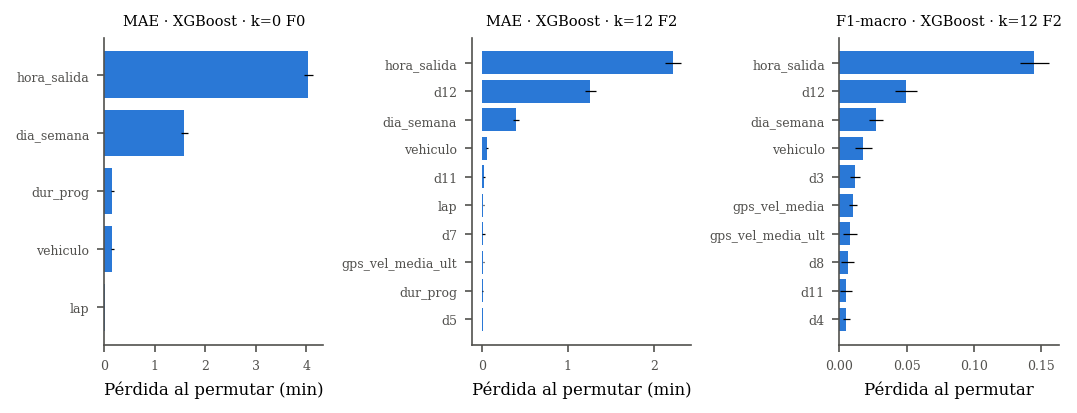

,variable,media,std,tarea,modelo,k,conjunto
0,hora_salida,4.0412,0.0939,reg,xgb,0,F0
1,dia_semana,1.5909,0.0620,reg,xgb,0,F0
3,dur_prog,0.1678,0.0320,reg,xgb,0,F0
4,vehiculo,0.1631,0.0293,reg,xgb,0,F0
2,lap,0.0222,0.0074,reg,xgb,0,F0
0,hora_salida,2.2246,0.0941,reg,xgb,12,F2
16,d12,1.2631,0.0682,reg,xgb,12,F2
1,dia_semana,0.3978,0.0306,reg,xgb,12,F2
4,vehiculo,0.0602,0.0146,reg,xgb,12,F2
15,d11,0.0283,0.0121,reg,xgb,12,F2


In [30]:
# ---------- Importancia por permutación en prueba (n_repeats = 10) ----------
def mejor_de(tarea, k, conj):
    return (mejores[(mejores.tarea == tarea) & (mejores.k == k) & (mejores.conjunto == conj)]
            .sort_values("metrica_media", ascending=(tarea == "reg")).modelo.iat[0])

casos = [("reg", 0, "F0"), ("reg", 12, "F2"), ("clf", 12, "F2")]
fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.8), dpi=150)
importancias = []
for ax, (tarea, k, conj) in zip(axs, casos):
    modelo = mejor_de(tarea, k, conj)
    X = XS[(k, conj)][modelo].iloc[IDX_TEST]
    pi = permutation_importance(FINALES[(tarea, modelo, k, conj)], X, yt[tarea], n_repeats=10, random_state=SEED,
                                scoring="neg_mean_absolute_error" if tarea == "reg" else "f1_macro", n_jobs=-1)
    imp = pd.DataFrame({"variable": X.columns, "media": pi.importances_mean, "std": pi.importances_std})
    imp = imp.sort_values("media", ascending=False)
    importancias.append(imp.assign(tarea=tarea, modelo=modelo, k=k, conjunto=conj))
    top = imp.head(10)[::-1]
    ax.barh(top.variable, top.media, xerr=top["std"], color=AZUL, error_kw={"lw": 0.6})
    ax.set_title(f"{'MAE' if tarea == 'reg' else 'F1-macro'} · {NOMBRES[modelo]} · k={k} {conj}", fontsize=7)
    ax.set_xlabel("Pérdida al permutar" + (" (min)" if tarea == "reg" else "")); ax.tick_params(labelsize=6)
guardar(fig, "res_importancia.png")
importancias = pd.concat(importancias)
display(importancias.groupby(["tarea", "k", "conjunto"]).head(8).round(4))


## 12. Reproducibilidad y exportación

- Guardar las tablas de resultados en CSV (`resultados_cv.csv`, `resultados_test.csv`) y las figuras en PNG a 300 dpi para el paper.
- Registrar las versiones de las librerías (celda de la etapa 0) en el paper (Sección V-F).
- Subir el notebook a GitHub **sin** los CSV de datos, y documentar en el README cómo obtenerlos.

In [31]:
mejores.to_csv(os.path.join(OUT_DIR, "resultados_cv_mejores.csv"), index=False)
resultados_test.to_csv(os.path.join(OUT_DIR, "resultados_test.csv"), index=False)
pruebas_h1.to_csv(os.path.join(OUT_DIR, "pruebas_h1_vs_lineas_base.csv"), index=False)
ablacion_h2.to_csv(os.path.join(OUT_DIR, "ablacion_h2_efecto_k.csv"), index=False)
ablacion_h3.to_csv(os.path.join(OUT_DIR, "ablacion_h3_gps.csv"), index=False)
importancias.to_csv(os.path.join(OUT_DIR, "importancia_permutacion.csv"), index=False)

# Predicciones por vuelta en prueba (permiten rehacer cualquier prueba estadística o gráfico)
pred_largo = []
for (tarea, modelo, k, conj), (pred, _) in PRED.items():
    pred_largo.append(pd.DataFrame({"id": vm.id.values[IDX_TEST], "tarea": tarea, "modelo": modelo, "k": k,
                                    "conjunto": conj, "real": yt[tarea], "pred": pred}))
pd.concat(pred_largo).to_csv(os.path.join(OUT_DIR, "predicciones_test.csv"), index=False)

with open(os.path.join(OUT_DIR, "versiones.json"), "w") as fh:
    json.dump(VERSIONES, fh, indent=2)
with open(os.path.join(OUT_DIR, "requirements.txt"), "w") as fh:
    fh.write("\n".join(f"{n}=={v}" for n, v in VERSIONES.items() if n != "python") + "\n")

print("Archivos en", OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print("  ", f)
print("Figuras en", FIG_DIR)
for f in sorted(os.listdir(FIG_DIR)):
    print("  ", f)


Archivos en /content/drive/MyDrive/AM2026-2/resultados
   ablacion_h2_efecto_k.csv
   ablacion_h3_gps.csv
   importancia_permutacion.csv
   predicciones_test.csv
   pruebas_h1_vs_lineas_base.csv
   requirements.txt
   resultados_cv_lineas_base.csv
   resultados_cv_mejores.csv
   resultados_cv_raw.csv
   resultados_test.csv
   tabla_cv_clf.csv
   tabla_cv_reg.csv
   versiones.json
Figuras en /content/drive/MyDrive/AM2026-2/fig
   eda1_hist_y.png
   eda2_hora_dia.png
   eda3_tramos.png
   eda4_mapa.png
   eda5_corr_k.png
   res_confusion.png
   res_h2_efecto_k.png
   res_importancia.png


### 12.1 Figuras del paper

Versiones a ancho de una columna (3,4 pulgadas), con los paneles apilados, de las figuras usadas en el paper (`fig/paper_*.png`).

In [32]:
# ---------- Figuras del paper (ancho de una columna, 3,4 pulgadas, paneles apilados) ----------
plt.rcParams.update({"font.size": 7})
def guardar_paper(fig, nombre):
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, nombre), dpi=300, bbox_inches="tight", pad_inches=0.02); plt.close(fig)

# Fig. 1 — ruta y PC
fondo = mon[["latitude", "longitude"]].sample(60000, random_state=0)
fondo = fondo[fondo.longitude.between(-72.01, -71.84) & fondo.latitude.between(-13.57, -13.51)]
off = {1:(4,-6),2:(3,4),3:(2,4),4:(0,5),5:(4,3),6:(-12,-6),7:(4,-4),8:(5,-2),9:(5,-2),10:(5,-3),
       11:(-14,-2),12:(-14,-2),13:(-14,3),14:(-3,-9),15:(-6,5),16:(-3,-9),17:(2,-9),18:(-6,-9)}
fig, ax = plt.subplots(figsize=(3.4, 2.2))
ax.scatter(fondo.longitude, fondo.latitude, s=0.05, c=GRIS, alpha=0.4, linewidths=0, rasterized=True)
for j, (la, lo) in enumerate(PCS, 1):
    ax.scatter(lo, la, s=9, c=AZUL, edgecolors="white", linewidths=0.5, zorder=3)
    ax.annotate(str(j), (lo, la), xytext=off[j], textcoords="offset points", fontsize=5.5)
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.set_xticks([-71.98, -71.94, -71.90, -71.86])
ax.set_aspect(1 / np.cos(np.radians(13.54)))
guardar_paper(fig, "paper_fig1_ruta.png")

# Fig. 2 — retraso por hora y por día
fig, axs = plt.subplots(2, 1, figsize=(3.4, 3.3))
gh = vy.groupby(np.floor(vy.hora_salida).astype(int)).y.agg(["mean", "size"]); gh = gh[gh["size"] >= 30]
axs[0].bar(gh.index, gh["mean"], color=[AZUL if v < 0 else ROJO for v in gh["mean"]], width=0.75)
axs[0].axhline(0, color="#52514e", lw=0.6); axs[0].axhline(UMBRAL_RETRASO, color="#52514e", lw=0.5, ls=":")
axs[0].text(4.6, 6.0, "umbral +5 min", fontsize=6, color="#52514e")
axs[0].set_xticks(gh.index); axs[0].set_xlabel("Hora programada de salida"); axs[0].set_ylabel("Retraso medio (min)")
axs[0].set_title("(a)", fontsize=7, loc="left")
gd = vy.groupby("dia_semana").y.agg(["mean", "sem"])
axs[1].bar([DIAS[d] for d in gd.index], gd["mean"], yerr=1.96 * gd["sem"],
           color=[ROJO if d == 5 else GRIS for d in gd.index], width=0.65, error_kw={"lw": 0.6})
for i, m in enumerate(gd["mean"]):
    axs[1].text(i, m + 1.2, f"{m:.1f}".replace(".", ","), ha="center", fontsize=6)
axs[1].set_ylabel("Retraso medio (min)"); axs[1].set_xlabel("Día de la semana"); axs[1].set_ylim(0, 13)
axs[1].set_title("(b)", fontsize=7, loc="left")
guardar_paper(fig, "paper_fig2_hora_dia.png")

# Fig. 3 — cambio del retraso por tramo
m_inc = np.nanmean(np.diff(D[ok], axis=1), 0); x = np.arange(1, 18)
fig, ax = plt.subplots(figsize=(3.4, 1.9))
ax.bar(x, m_inc, color=[AZUL if v < 0 else ROJO for v in m_inc], width=0.75); ax.axhline(0, color="#52514e", lw=0.6)
for xi, v in zip(x, m_inc):
    if abs(v) >= 1.5:
        ax.text(xi, v + (0.12 if v > 0 else -0.12), f"{v:+.2f}".replace(".", ","), ha="center",
                va="bottom" if v > 0 else "top", fontsize=5.5)
ax.set_xticks(x); ax.set_xticklabels([f"{j}-{j+1}" for j in range(1, 18)], rotation=90, fontsize=5.5)
ax.set_ylim(-2.6, 3.4); ax.set_xlabel("Tramo (PC origen – PC destino)"); ax.set_ylabel("Cambio medio (min)")
guardar_paper(fig, "paper_fig3_tramos.png")

# Fig. 4 — correlación por PC
fig, ax = plt.subplots(figsize=(3.4, 1.8))
ax.plot(range(1, 18), corr, marker="o", ms=2.5, color=AZUL, lw=1)
for kk in K_VALUES[1:]:
    ax.axvline(kk, color=GRIS, lw=0.6, ls=":")
ax.set_xticks(range(1, 18)); ax.set_ylim(-0.1, 1); ax.set_xlabel("Punto de control k"); ax.set_ylabel("corr(d$_k$, d$_{18}$)")
guardar_paper(fig, "paper_fig4_corr_k.png")

# Fig. 5 — efecto de k en prueba
NOM5 = {**NOMBRES, "B2 histórico": "B2 histórico/mayoritaria"}
fig, axs = plt.subplots(2, 1, figsize=(3.4, 3.6))
for ax, tarea, met, lab, tit in ((axs[0], "reg", "MAE", "MAE en prueba (min)", "(a) Regresión"),
                                 (axs[1], "clf", "F1_macro", "F1-macro en prueba", "(b) Clasificación")):
    t = resultados_test[(resultados_test.tarea == tarea) & (resultados_test.conjunto != "F2")]
    for modelo, g in t.groupby("modelo"):
        g = g.sort_values("k"); c, mk = ESTILO[modelo]
        ax.plot(g.k, g[met], "--" if modelo.startswith("B") else "-", marker=mk, color=c, ms=3.5, lw=1, label=NOM5[modelo])
    ax.set_xticks(K_VALUES); ax.set_ylabel(lab); ax.set_title(tit, fontsize=7, loc="left")
axs[1].set_xlabel("Puntos de control observados (k)")
h1, l1 = axs[0].get_legend_handles_labels(); h2, l2 = axs[1].get_legend_handles_labels()
leyenda = dict(zip(l1 + l2, h1 + h2))
fig.legend(leyenda.values(), leyenda.keys(), fontsize=5.8, frameon=False, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(os.path.join(FIG_DIR, "paper_fig5_efecto_k.png"), dpi=300, bbox_inches="tight", pad_inches=0.02); plt.close(fig)

# Fig. 6 — matrices de confusión de XGBoost (k = 0 y k = 12)
fig, axs = plt.subplots(1, 2, figsize=(3.4, 1.75))
etiquetas = ["Adel.", "Punt.", "Retr."]
for ax, (k, conj) in zip(axs, [(0, "F0"), (12, "F1")]):
    cm = confusion_matrix(yt["clf"], PRED[("clf", "xgb", k, conj)][0], labels=[0, 1, 2])
    ax.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6.5, color="white" if cm[i, j] > 200 else "black")
    ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(etiquetas, fontsize=6); ax.set_yticklabels(etiquetas, fontsize=6)
    ax.set_xlabel("Predicha", fontsize=6.5); ax.set_ylabel("Real", fontsize=6.5); ax.set_title(f"k = {k}", fontsize=7)
    for s in ax.spines.values():
        s.set_visible(False)
guardar_paper(fig, "paper_fig6_confusion.png")

# Fig. 7 — importancia por permutación (paneles apilados)
titulos = {("reg", 0, "F0"): "(a) Regresión, k = 0 (pérdida de MAE, min)",
           ("reg", 12, "F2"): "(b) Regresión, k = 12, F2 (pérdida de MAE, min)",
           ("clf", 12, "F2"): "(c) Clasificación, k = 12, F2 (pérdida de F1-macro)"}
fig, axs = plt.subplots(3, 1, figsize=(3.4, 4.6), gridspec_kw={"height_ratios": [5, 8, 8]})
for ax, (caso, tit) in zip(axs, titulos.items()):
    q = (importancias[(importancias.tarea == caso[0]) & (importancias.k == caso[1]) & (importancias.conjunto == caso[2])]
         .sort_values("media", ascending=False).head(8)[::-1])
    ax.barh(q.variable, q.media, xerr=q["std"], color=AZUL, height=0.6, error_kw={"lw": 0.6})
    ax.set_title(tit, fontsize=7, loc="left"); ax.tick_params(labelsize=6)
guardar_paper(fig, "paper_fig7_importancia.png")
plt.rcParams.update({"font.size": 8})
print("Figuras del paper guardadas en", FIG_DIR)


Figuras del paper guardadas en /content/drive/MyDrive/AM2026-2/fig
